# Why random nudges stopped changing the algorithm
**Plan-noise crosswalk on Qwen3-8B: dose unit × direction seeds** — iteration 7, step K of a study of whether an LLM can be pushed, from *inside*, into writing a different algorithm than its default one.

**Background.** Qwen3-8B (instruct, bf16, thinking off) nearly always writes one default algorithm per task. For **T10**, *"write `solve(n, edges)` that returns the number of connected components of an undirected graph"*, it writes **union-find** on 50 of 50 clean samples. A prompt *ban* ("Do not use union-find (disjoint set union) for this task.") does move it, and the ban leaves a measurable displacement in the residual stream at the task-specification tokens. Every prompt has a length-matched **twin** in which the banned name is replaced by an unrelated noun ("Do not use ship for this task. . . . . . . ."). Plan noise is applied to the twin, and the unpushed twin is each slot's clean reference. **Plan noise (PN)** asks whether a *random* internal push does the same as the ban. During the prompt prefill only, a fresh isotropic random direction `u` (one per sample) is pushed into decoder blocks 12–23 at the task-spec positions. The edit is displacement-targeted:

`h ← h + (α·n[l,p] − (h − h_twin)·u) u`

so the displacement from the clean twin prompt along `u` is exactly `α·n[l,p]` in every edited (block, position) cell.

**The puzzle.** Iteration 4's PN moved T10 off union-find on 25/50 programs. Iteration 5's PN moved it on 1/50. The two codes differ in two ways:
1. **The dose unit `n[l,p]`.**
   - `U_abs` (iteration 4) is the norm of the displacement that the real ban writes into that cell.
   - `U_bf` (iteration 5) is `‖h_twin[l,p]‖ · r_Q(l)`, a "ban-free" fixed fraction of the cell's own residual norm.
2. **The direction seeds.** `S4 = PCG64(stable_seed(task,'PN_a<α>',w,k))` vs `S5 = PCG64(stable_seed(task,'PN5',w,k))`.

Step K crosses the two factors on shared **common-random-number (CRN) slots**. Every arm of a slot `(template w, sample k)` decodes the same prompt with the same sampler uniforms, so arms differ only in the internal push:

| design | dose unit | seeds |
|---|---|---|
| D1 | U_abs | S4 — iteration 4's design |
| D2 | U_abs | S5 |
| D3 | U_bf | S4 |
| D4 | U_bf | S5 — iteration 5's design |
| D5 | U_bf* = U_bf's profile at U_abs's per-block energy | S4 |
| P_top / P_rest / P_shuf | U_abs on its top-quartile cells only / on the other cells / with spec positions permuted | S4 |

**Published answer: the UNIT.** At α 2 on T10, D1–D4 move 0.50 / 0.52 / 0.10 / 0.02 of the programs to a correct named off-default algorithm (DFS, BFS). The unit effect is +0.45 [0.35, 0.55] and the seed effect +0.03 [−0.07, 0.14]. Pushes act where bans write: U_abs's top-quartile cells move 29/50, the other cells 15/50, and position-shuffled pushes 4/50.

**What this notebook runs.** `method.py` is the artifact's entry point and dispatches 19 steps, each a module in `src/`. **Not re-run here:** the generation steps, which need Qwen3-8B in bf16 on a ≥20 GB GPU. **Re-run here**, on CPU with the original code split into cells, is everything computed from the generated programs:
- the dose units and direction seeds (`src/k_units.py`), and the edit itself (`make_edits_v4`, `make_edits_masked`) checked on toy tensors;
- the anchors and the S1 2×2: bootstrap CIs, sign-flip tests, Holm and the conditional logit. Also the D5 split and the mediation (`src/analysis_k.py`);
- the S2 profile tests, the E1 dose sweep, the E3 replication (`src/extensions_k.py`) and the E2 geometry (`src/geometry_k.py`);
- the figures (`src/figures_k.py`), including a PCA of the actual block-35 residual-stream displacement vectors.

**Data.** `mini_demo_data.json` holds all 100 T10 CRN slots of the artifact (5 templates × k 0–19): 1,250 generated programs with their labels, pass flags, code and realised displacement. It also carries the T10 dose-unit maps and 350 block-35 displacement vectors (fp16).

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (method.py and every src/ module log through it)
_pip('loguru==0.7.3')

# numpy, scipy, scikit-learn, statsmodels, pandas, matplotlib, torch — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'statsmodels==0.14.6', 'pandas==2.2.2',
         'matplotlib==3.10.0')
    _pip('torch==2.9.0', '--index-url', 'https://download.pytorch.org/whl/cpu')   # Colab's torch 2.9.0, CPU wheel

In [2]:
from __future__ import annotations

# --- method.py ---
import os
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# --- src/k_cfg.py ---
import hashlib
import json
import math
from datetime import datetime, timezone
from typing import Any, Callable, Iterable

# --- src/analysis_k.py ---
import itertools
from collections import Counter, defaultdict

import numpy as np

# --- src/gen_k.py and the vendored exp22 hooks4.py (the edit) ---
import torch

# --- notebook additions: decoding the fp16 vectors, figures, tables ---
import base64
import warnings
import matplotlib.pyplot as plt
import pandas as pd

# statsmodels' ConditionalLogit warns on every fit that slots with the same outcome under all four designs carry no
# conditional information and are dropped -- expected for a paired 2x2, so silenced to keep the outputs readable
warnings.filterwarnings("ignore", message="Dropped .* groups and .* observations for having no within-group variance")
print("numpy", np.__version__, "| torch", torch.__version__, "| pandas", pd.__version__)

numpy 2.0.2 | torch 2.9.0+cpu | pandas 2.2.2


In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-7/experiment-36/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
EX = data["datasets"][0]["examples"]          # one example = one CRN slot (task T10, template w, sample k)
print(data["metadata"]["description"])
print(f"\n{len(EX)} CRN slots | {sum(len(e['metadata_programs']) for e in EX)} generated programs | "
      f"{sum(len(e['metadata_R35_fp16_b64']) for e in EX)} block-35 displacement vectors")
print("\nfirst slot:", EX[0]["input"].splitlines()[0], "-> twin wrote", EX[0]["output"],
      "| D1 at alpha 2 wrote", EX[0]["predict_D1_a2"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Iteration-7 step K of the plan-noise study on Qwen/Qwen3-8B (rev b968826d, bf16, thinking off). Demo subset: task T10 (connected components), 100 CRN slots (W1-W5 x k 0-19); every slot carries the clean twin and every pushed arm (dose unit x direction seeds x alpha) with its label, pass flag, validity, realised displacement summary and code.

100 CRN slots | 1250 generated programs | 350 block-35 displacement vectors

first slot: [task T10 | template W1 | CRN slot k=0] -> twin wrote union_find|True | D1 at alpha 2 wrote union_find|True


## Configuration
Only the resampling sizes of the statistics drive the runtime. The values below are the artifact's original ones: 2,000 bootstrap replicates and 100,000 Monte-Carlo sign flips. With them, the whole notebook ran in about 40 s on a 2-core CPU, install cell included. That was measured over three test runs, scaling from 20 / 1,000 through 200 / 10,000 to these values.

For a faster pass, lower them, for example to `N_BOOT = 200` and `N_FLIP = 10_000`. Counts, shares, McNemar tables and decisions do not depend on these values; the CI endpoints and Monte-Carlo p-values do. After changing them, re-run the cells below, because `boot_ci` and `sign_flip_p` bind these values when they are defined.

In [5]:
# ---- tunable parameters (original values in the comments) ----
N_BOOT = 2000          # slot-cluster bootstrap replicates behind every 95% CI              (original: 2000)
N_FLIP = 100_000       # Monte-Carlo sign flips when a contrast has > 20 non-zero slots      (original: 100_000)
BOOT_SEED = 20261022   # seed of the bootstraps and of the Monte-Carlo sign flips            (original: 20261022)

## 1. The pipeline (`method.py`)
`method.py` is only a dispatcher. `uv run method.py <step>` does three things:
- runs every step as a separate process (`run`);
- starts the label worker in the background (`start_labeller`). The worker runs each generated program on hidden tests and classifies its algorithm from runtime behaviour plus the AST, calling an LLM judge only when the two disagree;
- makes `commit2`, `analyse` and `prices` wait until every program is labelled (`wait_labelled`).

Two hash-chained commits pre-register the predictions and the analysis code before the first decisive row exists. The cell below is `method.py`'s step table verbatim, annotated with what this notebook re-runs.

In [6]:
# ---- method.py: the step table (verbatim) ----
STEPS: dict[str, list[list[str]]] = {
    "setup": [["src/setup_inputs.py"]],
    "gates": [["src/s3_prices.py", "g5"], ["src/cpu_gates.py"]],
    "gpu0": [["src/gen_k.py", "tests", "s0"]],
    "commit1": [["src/make_commits.py", "commit1"]],
    "gpu1": [["src/gen_k.py", "s1", "d5", "s2"]],
    "commit2": [["src/make_commits.py", "commit2"]],
    "gpu2": [["src/gen_k.py", "s3pn"]],
    "knobs": [["src/knobs_k.py", "base,reuse,check,verdict,rerun"]],
    "units": [["src/dump_units.py"]],
    "e1": [["src/e1_sweep.py"]],
    "analyse": [["src/analysis_k.py", "all"]],
    "prices": [["src/s3_prices.py", "prices"], ["src/s3_prices.py", "retag"]],
    "novelty": [["src/novelty_k.py"], ["src/novelty_k.py", "--manual-only"]],
    "geometry": [["src/geometry_k.py"]],
    "figures": [["src/figures_k.py"]],
    "report": [["src/report_k.py"]],
    "rederive": [["audit/rederive.py"]],
    "outputs": [["src/outputs_k.py"]],
}
ORDER = ["setup", "gates", "label", "gpu0", "commit1", "gpu1", "commit2", "gpu2", "knobs", "units", "e1", "analyse",
         "prices", "novelty", "geometry", "figures", "report", "rederive", "outputs"]

# notebook addition: the steps this notebook re-runs inline (CPU, from mini_demo_data.json)
IN_THIS_NOTEBOOK = {
    "gpu0": "section 6: the edit arithmetic of GPU unit test U2, on toy tensors (no model)",
    "units": "section 5: dose units U_abs / U_bf / U_bf* / P_top / P_rest / P_shuf of T10",
    "analyse": "sections 8-11: anchors, S1 2x2, D5 split, mediation, S2, E1",
    "geometry": "section 13: E2 slot concordance and fixed-dose AUCs",
    "figures": "section 14: F1-F5, E1, E3",
}
for s in ORDER:
    cmd = "; ".join(" ".join(c) for c in STEPS.get(s, [["src/label_k.py (background worker)"]]))
    print(f"{s:<9} {cmd:<55} {'<- ' + IN_THIS_NOTEBOOK[s] if s in IN_THIS_NOTEBOOK else ''}")
print("\n(E3's analysis, src/extensions_k.py, ran outside the step table; section 12 re-runs it.)")

setup     src/setup_inputs.py                                     
gates     src/s3_prices.py g5; src/cpu_gates.py                   
label     src/label_k.py (background worker)                      
gpu0      src/gen_k.py tests s0                                   <- section 6: the edit arithmetic of GPU unit test U2, on toy tensors (no model)
commit1   src/make_commits.py commit1                             
gpu1      src/gen_k.py s1 d5 s2                                   
commit2   src/make_commits.py commit2                             
gpu2      src/gen_k.py s3pn                                       
knobs     src/knobs_k.py base,reuse,check,verdict,rerun           
units     src/dump_units.py                                       <- section 5: dose units U_abs / U_bf / U_bf* / P_top / P_rest / P_shuf of T10
e1        src/e1_sweep.py                                         
analyse   src/analysis_k.py all                                   <- sections 8-11: anchors, S1 2x2, D5 s

## 2. Constants and helpers (`src/k_cfg.py`)
Three adaptations from the original:
- **Paths.** They point to local output folders (`results/`, `figures/`, `logs/` next to the notebook).
- **`S1_TASKS`.** Restricted to T10, because the demo data ships that task only. The artifact also ran T2 (shortest weighted paths, default Dijkstra), which replicates the result.
- **The `_Module` shim.** It stands in for the artifact's cross-module imports (`import k_cfg as K`, `import k_units as KU`, `import analysis_k as A`), so the copied functions keep their `K.` / `KU.` / `A.` prefixes unchanged.

In [7]:
# ---- src/k_cfg.py (paths -> local output folders; constants of the GPU runner, commit chain and judges omitted) ----
ROOT = Path.cwd()          # demo: the notebook's folder (original: the artifact folder)
RESULTS = ROOT / "results"
FIGS = ROOT / "figures"
LOGS = ROOT / "logs"
for _d in (RESULTS, FIGS, LOGS):
    _d.mkdir(parents=True, exist_ok=True)

# method.py's logging setup
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(str(LOGS / "method.log"), rotation="30 MB", level="DEBUG")

MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
PRECISION = "BF16 weights and activations (HF transformers 4.57.6, sdpa, torch 2.8.0+cu128); engine d of exp29"
TEMPLATES = ("W1", "W2", "W3", "W4", "W5")
S1_TASKS = ("T10",)        # demo: the data ships T10 only (original: ("T10", "T2"))
D5_TASKS = ("T03", "T10", "T2", "T05", "T1")          # S3 decisive tasks (exp27 D5)
EDIT_BLOCKS = list(range(12, 24))
ALL_BLOCKS = list(range(36))
D_MODEL = 4096
FENCE = {"T10": "bench", "T03": "bench", "T05": "bench", "T2": "path", "T1": "path"}
MAX_NEW = {"T10": 1024, "T03": 1024, "T05": 1024, "T2": 1536, "T1": 1536}
DEFAULTS = {"T10": "union_find", "T2": "dijkstra", "T03": "full_sort", "T05": "hash_map", "T1": "bfs"}
DESIGNS = ("D1", "D2", "D3", "D4", "D5")
PROFILES = ("PTOP", "PREST", "PSHUF")
DESIGN_DEF = {"D1": ("U_abs", "S4"), "D2": ("U_abs", "S5"), "D3": ("U_bf", "S4"), "D4": ("U_bf", "S5"),
              "D5": ("U_bf_star", "S4"), "PTOP": ("P_top", "S4"), "PREST": ("P_rest", "S4"),
              "PSHUF": ("P_shuf", "S4")}
K10 = list(range(10))
K20 = list(range(20))


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def stable_seed(*parts: Any) -> int:
    """exp8/exp17/exp19 convention: sha256 of the '|'-joined str() of the parts, mod 2^63."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def _json_default(o: Any) -> Any:
    try:
        import numpy as np
        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, np.bool_):
            return bool(o)
    except ImportError:
        pass
    return str(o)


def write_json(p: Path, obj: Any) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=1, default=_json_default))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def row_key(r: dict[str, Any]) -> str:
    return f"{r['task']}|{r['template']}|{r['arm']}|{r['sample_id']}"


def parse_arm(arm: str) -> dict[str, Any]:
    if arm == "TWIN":
        return {"family": "TWIN", "design": "TWIN", "alpha": None}
    d, a = arm.rsplit("_a", 1)
    unit, seeds = DESIGN_DEF[d]
    return {"family": "S2" if d in PROFILES else "S1", "design": d, "alpha": float(a), "unit": unit, "seeds": seeds}


def s4_arm(alpha: float) -> str:
    """exp29/exp19 PN arm string used inside the S4 seed (asserted against logged seeds in gate G3)."""
    return "PN_a1" if float(alpha) == 1.0 else "PN_a2"


def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


class _Module:
    """Stands in for `import k_cfg as K`, `import k_units as KU` and `import analysis_k as A`: every module of the
    artifact lives in this notebook's namespace, so K.x / KU.x / A.x simply look x up there."""
    def __getattr__(self, name: str) -> Any:
        return globals()[name]


K = KU = A = _Module()

## 3. The generated programs
In the artifact, the generated programs (`data/raw/raw_k.jsonl`: text, token ids, slot, design, α, seeds, realised displacement) and their labels (`data/labels.jsonl`) live in two files, joined by the row key `<task>|<template>|<arm>|<sample_id>`. The demo data carries one joined record per program. The cell below splits each record back into its two halves, so that `load_joined` recomputes every outcome from the raw label, pass flag and validity.

In [8]:
# Split each joined program record back into its raw-row half and its label half
RAW_FIELDS = ("task", "template", "arm", "design", "alpha", "stage", "unit_id", "seed_scheme", "direction_seed",
              "realised_disp", "unit_mean_b12", "finish_reason", "n_tokens")
raw_rows, label_rows = [], []
for e in EX:
    for p in e["metadata_programs"]:
        raw_rows.append({**{f: p[f] for f in RAW_FIELDS}, "sample_id": p["k"]})
        label_rows.append({"key": p["key"], "label": p["label"], "passed": p["passed"], "valid": p["valid"]})
print(f"{len(raw_rows)} programs over {len({(r['template'], r['sample_id']) for r in raw_rows})} CRN slots")
print(pd.Series(Counter(r["arm"] for r in raw_rows)).sort_index().to_frame("programs").T.to_string())

1250 programs over 100 CRN slots
          D1_a1  D1_a2  D2_a1  D2_a2  D3_a1  D3_a2  D3_a3  D3_a4  D3_a6  D4_a1  D4_a2  D5_a2  PREST_a2  PSHUF_a2  PTOP_a2  TWIN
programs     50    100     50    100     50    100     50     50     50     50    100    100       100       100      100   100


## 4. Outcomes (`src/analysis_k.py`, part 1)
Each program gets three outcomes; invalid and failing programs count as not-target:
- **Y** (primary): the program passed the hidden tests **and** implements a *named catalogue* algorithm other than the default. For T10 that means BFS, DFS or label propagation instead of union-find.
- **Y_any**: passed, and anything but the default. This adds correct "other" programs.
- **A** (attempt): a valid program whose algorithm is off-default, whether or not it passes.

Two adaptations: `catalogue()` reads the vendored task catalogue, which ships in the data file for T10; `load_joined` takes the two in-memory halves instead of two file paths.

In [9]:
# ---- src/analysis_k.py: constants ----
# N_BOOT, N_FLIP, BOOT_SEED: see the configuration cell
NOT_TARGET = {"invalid", "disputed", "unknown"}
EXP29_D1 = {"T10": {"attempts": 25, "N": 50, "pass": 0.98}, "T2": {"attempts": 22, "N": 50, "pass": 0.62,
                                                                 "correct_off_default": 9}}
EXP27_D4_T10 = {"correct_off_default": 1, "N": 50}
A1_MIN_K = 15
FISHER_P = 0.05
MOVABLE_EXCESS = 0.20
PASS_FRAC = 0.8
TIE_BAND = 0.10
# AMENDMENT 3 (after the exploratory E3 rows added T10 slots k 10-19 to the same arms): every committed S1 analysis
# reads only its committed slots, so exploratory rows never enter it (reproduces the pre-E3 numbers exactly).
COMMITTED_KS = {("T10", 1.0): list(range(10)), ("T10", 2.0): list(range(10)), ("T2", 1.0): list(range(10)),
                ("T2", 2.0): list(range(20))}


# ------------------------------------------------------------------------------------------------ catalogue
def catalogue(task: str) -> set[str]:
    # demo: the vendored exp11 catalogue (bench.common.catalogue.TASKS[task]["modes"]) ships in the data file for T10
    # (original: cfg4.PATH_CATALOGUE for T1/T2, the exp11 catalogue module for the bench tasks)
    TASKS = {data["metadata"]["task"]: {"modes": data["metadata"]["catalogue_modes"]}}
    return set(TASKS[task]["modes"])


_CAT: dict[str, set[str]] = {}


def outcomes(task: str, lab: dict[str, Any] | None) -> dict[str, Any]:
    if task not in _CAT:
        _CAT[task] = catalogue(task)
    if lab is None:
        return {"labelled": False}
    label = lab["label"]
    d = DEFAULTS[task]
    passed = bool(lab.get("passed"))
    valid = bool(lab.get("valid"))
    off = label not in NOT_TARGET and label != d
    return {"labelled": True, "label": label, "passed": passed, "valid": valid,
            "Y": int(passed and label in _CAT[task] and label != d),
            "Y_any": int(passed and off), "A": int(valid and off), "disputed": int(label == "disputed")}


def load_joined(raw_rows: list[dict[str, Any]], label_rows: list[dict[str, Any]]) -> list[dict[str, Any]]:
    # demo: the two halves come from the data file (original: load_joined(raw_path=RAW, labels_path=LABELS) read
    # data/raw/raw_k.jsonl and data/labels.jsonl)
    labs = {l["key"]: l for l in label_rows}
    out = []
    for r in raw_rows:
        o = outcomes(r["task"], labs.get(row_key(r)))
        out.append({"key": row_key(r), "task": r["task"], "template": r["template"], "arm": r["arm"],
                    "k": int(r["sample_id"]), "design": r.get("design"), "alpha": r.get("alpha"),
                    "stage": r.get("stage"), "unit_id": r.get("unit_id"), "seed_scheme": r.get("seed_scheme"),
                    "direction_seed": r.get("direction_seed"), "realised_disp": r.get("realised_disp"),
                    "unit_mean_b12": r.get("unit_mean_b12"), "finish_reason": r.get("finish_reason"),
                    "n_tokens": r.get("n_tokens"), **o})
    return out


def cell(rows: list[dict[str, Any]], task: str, arm: str, ks: list[int] | None = None) -> dict[tuple, dict]:
    sel = {}
    for r in rows:
        if r["task"] == task and r["arm"] == arm and r.get("labelled") and (ks is None or r["k"] in ks):
            sel[(r["template"], r["k"])] = r
    return sel


def share(sel: dict[tuple, dict], key: str) -> dict[str, Any]:
    n = len(sel)
    k = sum(r[key] for r in sel.values())
    lo, hi = wilson(k, n)
    return {"k": k, "n": n, "share": k / n if n else None, "wilson95": [lo, hi]}


def describe(sel: dict[tuple, dict]) -> dict[str, Any]:
    n = len(sel)
    comp = Counter(r["label"] for r in sel.values())
    comp_correct = Counter(r["label"] for r in sel.values() if r["passed"])
    return {"N": n, "Y": share(sel, "Y"), "Y_any": share(sel, "Y_any"), "A": share(sel, "A"),
            "pass_rate": (sum(r["passed"] for r in sel.values()) / n) if n else None,
            "disputed": sum(r["disputed"] for r in sel.values()), "composition": dict(comp),
            "composition_correct": dict(comp_correct),
            "length_finish": sum(r.get("finish_reason") == "length" for r in sel.values())}

In [10]:
rows = load_joined(raw_rows, label_rows)

# sanity check: the outcomes recomputed from (label, passed, valid) equal those in the artifact's data/samples.jsonl
stored = {p["key"]: p for e in EX for p in e["metadata_programs"]}
mismatch = sum(any(r[f] != stored[r["key"]][f] for f in ("Y", "Y_any", "A")) for r in rows)
print(f"{len(rows)} joined rows | T10 catalogue {sorted(_CAT['T10'])}, default {DEFAULTS['T10']!r} | "
      f"outcome mismatches vs the artifact: {mismatch}")

# what an escape looks like: one CRN slot, the same prompt and the same sampler uniforms; only the internal push differs
slot = next(e for e in EX if e["output"] == "union_find|True" and e.get("predict_D1_a2") == "dfs|True")
progs = {p["arm"]: p for p in slot["metadata_programs"]}
for arm in ("TWIN", "D1_a2"):
    p = progs[arm]
    print(f"\n----- {slot['input'].splitlines()[0]}   arm {arm}: label {p['label']}, passed {p['passed']} -----")
    print(p["code"])

1250 joined rows | T10 catalogue ['bfs', 'dfs', 'label_propagation', 'union_find'], default 'union_find' | outcome mismatches vs the artifact: 0

----- [task T10 | template W1 | CRN slot k=3]   arm TWIN: label union_find, passed True -----
def solve(n, edges):
    parent = list(range(n))
    
    def find(x):
        if parent[x] != x:
            parent[x] = find(parent[x])
        return parent[x]
    
    def union(x, y):
        root_x = find(x)
        root_y = find(y)
        if root_x != root_y:
            parent[root_y] = root_x
    
    for u, v in edges:
        union(u, v)
    
    components = set()
    for i in range(n):
        components.add(find(i))
    
    return len(components)


----- [task T10 | template W1 | CRN slot k=3]   arm D1_a2: label dfs, passed True -----
def solve(n, edges):
    def dfs(node):
        visited.add(node)
        for neighbor in adj[node]:
            if neighbor not in visited:
                dfs(neighbor)
    
    adj = [[] for _ in rang

## 5. Dose units and direction seeds (`src/k_units.py`)
- **`U_abs[l, p]`**: the ban's own displacement norm. It measures how far the ban sentence moves the residual stream at block `l`, task-spec token `p`, relative to its length-matched twin prompt (measured in exp13/exp19; one map per task). It is a [12 × |S|] map: blocks 12–23 × 145 spec tokens for T10.
- **`U_bf[l, p] = ‖h_twin[l, p]‖ · r_Q(l)`**: iteration 5's ban-free unit. It is the twin's own residual norm times a per-depth ratio `r_Q`, exp23's median relative ban displacement of Qwen at that depth.
- **`U_bf*`**: U_bf's within-block profile rescaled to U_abs's per-block energy (design D5).
- **`P_top`, `P_rest`, `P_shuf`**: U_abs restricted to its top-quartile cells, to the other cells, or with its spec positions permuted. `P_top` and `P_rest` are rescaled to U_abs's Frobenius norm, and their masked cells are not edited.
- **`S4`, `S5`**: two seed schemes for the per-sample isotropic direction `u ∈ R^4096`.

The loaders read the T10 maps and the `r_Q` table from the data file instead of `.npz`/`.json` files. Everything else is verbatim.

In [11]:
# ---- src/k_units.py ----
PATH_TASKS = ("T1", "T2")


def u_abs(task: str) -> np.ndarray:
    """exp22 ctx4.ban_unit(task) (== exp19 load_norms(task, 'stage1')): float32 [12, |S|]."""
    # demo: the T10 unit ships in the data file (original: np.load(exp13 norms_<task>.npz)["norm"], or
    # np.load(exp17 norms_<task>.npy) for the path tasks)
    return np.array(data["metadata"][f"units_{task}"]["U_abs"], dtype=np.float32)


def r_q_table() -> tuple[np.ndarray, np.ndarray]:
    q = data["metadata"]["r_Q"]          # demo: exp23 results/qwen_ratio.json['r_Q'], shipped in the data file
    d = np.array([v["depth"] for v in q.values()])
    r = np.array([v["median"] for v in q.values()])
    o = np.argsort(d)
    return d[o], r[o]


_RQ: tuple[np.ndarray, np.ndarray] | None = None


def r_at(l: int) -> float:
    """exp27 gen5.r_at, verbatim."""
    global _RQ
    if _RQ is None:
        _RQ = r_q_table()
    return float(np.interp((l + 1) / 36, _RQ[0], _RQ[1]))


def s4_direction(task: str, alpha: float, w: str, k: int) -> tuple[int, np.ndarray]:
    """exp29 gen.pn_direction(task, arm, w, k) with arm = 'PN_a1' / 'PN_a2', verbatim arithmetic."""
    seed = stable_seed(task, s4_arm(alpha), w, k)
    x = np.random.Generator(np.random.PCG64(seed)).standard_normal(4096)
    return seed, (x / np.linalg.norm(x)).astype(np.float32)


def s5_direction(task: str, w: str, k: int, tag: str = "PN5") -> tuple[int, np.ndarray]:
    """exp27 gen5.pn5_direction, verbatim arithmetic (same u at alpha 1 and 2)."""
    seed = stable_seed(task, tag, w, k)
    x = np.random.Generator(np.random.PCG64(seed)).standard_normal(D_MODEL)
    return seed, (x / np.linalg.norm(x)).astype(np.float32)


def direction(seeds: str, task: str, alpha: float, w: str, k: int) -> tuple[int, np.ndarray]:
    return s4_direction(task, alpha, w, k) if seeds == "S4" else s5_direction(task, w, k)


def profile_masks(n: np.ndarray, task: str) -> dict[str, dict[str, np.ndarray]]:
    """S2 profiles of U_abs: unit [12, |S|] float32 and edit mask [12, |S|] bool for P_top, P_rest, P_shuf."""
    n = n.astype(np.float64)
    q75 = float(np.percentile(n, 75))
    top = n >= q75
    rest = ~top
    fro = float(np.linalg.norm(n))
    out = {}
    for name, m in (("P_top", top), ("P_rest", rest)):
        part = n * m
        scale = fro / float(np.linalg.norm(part))
        out[name] = {"unit": (part * scale).astype(np.float32), "mask": m.copy(), "scale": scale,
                     "energy_share": float((part ** 2).sum() / (n ** 2).sum()), "q75": q75}
    perm = np.random.Generator(np.random.PCG64(stable_seed(task, "SHUF"))).permutation(n.shape[1])
    out["P_shuf"] = {"unit": n[:, perm].astype(np.float32), "mask": np.ones_like(top), "perm": perm.tolist(),
                     "scale": 1.0, "energy_share": 1.0, "q75": q75}
    return out


def bf_star(u_bf: np.ndarray, n_abs: np.ndarray) -> np.ndarray:
    """U_bf*[l, :] = U_bf[l, :] * ||U_abs[l, :]|| / ||U_bf[l, :]|| (float64 arithmetic, float32 result)."""
    ub = u_bf.astype(np.float64)
    na = n_abs.astype(np.float64)
    s = np.linalg.norm(na, axis=1) / np.linalg.norm(ub, axis=1)
    return (ub * s[:, None]).astype(np.float32)


def dose_ratios(unit: np.ndarray, ref: np.ndarray) -> dict[str, float]:
    """Dose of a unit relative to D1's U_abs: mean of per-cell ratios, ratio of Frobenius norms, block-12 means."""
    u = unit.astype(np.float64)
    r = ref.astype(np.float64)
    return {"mean_cell_ratio": float((u / np.maximum(r, 1e-6)).mean()),
            "fro_ratio": float(np.linalg.norm(u) / np.linalg.norm(r)),
            "b12_mean_ratio": float(u[0].mean() / r[0].mean())}

### 5a. The two units in activation coordinates
The GPU runner builds `U_bf` from the twin's prefill (`gen_k.TaskCtxK.twin`: `‖h_twin[l, p]‖ · r_at(l)`), and `src/dump_units.py` dumped the twin norms `‖h_twin‖` of every template. Recomputing `U_bf` from those norms reproduces the dumped unit up to the data file's 4-decimal rounding. The table is `dump_units.py`'s per-template record, and it shows the key asymmetry between the two units:
- **U_abs is peaky.** Its top quartile of cells carries 81% of its energy. At α 2 its largest cell dose is about 2× that cell's own residual norm (`U_abs_over_hnorm_max` ≈ 1.05 on W1).
- **U_bf is flat by construction.** Its top quartile carries 42%, and its peak dose at α 2 is 0.25× the residual norm.

Two summaries of their size disagree, which is the confound that the D5 arm (`U_bf*`) splits. The per-block mean norms of U_bf are 0.66–0.79× those of U_abs, but the mean per-position ratio is ≈ 1.0. The total Frobenius ratio is 0.62.

In [12]:
units = data["metadata"]["units_T10"]
n_abs = u_abs("T10")
prof = profile_masks(n_abs, "T10")
summary = {}
for w in TEMPLATES:
    h_norm = np.array(units[f"h_norm_{w}"], dtype=np.float32)
    # gen_k.TaskCtxK.twin (exp27 Ctx.banfree): n_bf = ||h_twin[l, p]|| * r_Q(l)
    n_bf = np.stack([h_norm[j] * r_at(l) for j, l in enumerate(EDIT_BLOCKS)]).astype(np.float32)
    dumped = np.array(units[f"U_bf_{w}"], dtype=np.float32)
    # dump_units.py: the per-template record (verbatim arithmetic)
    ub, ua = n_bf.astype(np.float64), n_abs.astype(np.float64)
    summary[w] = {"U_bf recomputed - dumped (max abs)": float(np.abs(n_bf - dumped).max()),
                  "fro_ratio_total": float(np.linalg.norm(ub) / np.linalg.norm(ua)),
                  "U_abs_over_hnorm_max": float((ua / h_norm).max()),
                  "U_bf_over_hnorm_max": float((ub / h_norm).max()),
                  "top_quartile_energy_share_U_abs": float(prof["P_top"]["energy_share"]),
                  "top_quartile_energy_share_U_bf": float(((ub * prof["P_top"]["mask"]) ** 2).sum() / (ub ** 2).sum()),
                  "ratio_of_mean_norms (b12..b23)": f"{(ub.mean(1) / ua.mean(1)).min():.2f}..{(ub.mean(1) / ua.mean(1)).max():.2f}",
                  "mean_per_position_ratio (mean)": float((ub / ua).mean(1).mean())}
pub_units = data["metadata"]["published"]["unit_profiles_T10"]
tab = pd.DataFrame(summary).T
tab["fro_ratio_total (published)"] = [pub_units[w]["fro_ratio_total"] for w in TEMPLATES]
print(tab.to_string(float_format=lambda x: f"{x:.4g}"))

# dose of every unit relative to D1's U_abs (gen_k stores this per pushed row as dose_vs_D1), template W1
u_bf_w1 = np.array(units["U_bf_W1"], dtype=np.float32)
unit_maps = {"U_abs": n_abs, "U_bf": u_bf_w1, "U_bf*": bf_star(u_bf_w1, n_abs), "P_top": prof["P_top"]["unit"],
             "P_rest": prof["P_rest"]["unit"], "P_shuf": prof["P_shuf"]["unit"]}
print("\ndose_ratios vs U_abs (T10, W1):")
print(pd.DataFrame({k: dose_ratios(v, n_abs) for k, v in unit_maps.items()}).round(3).to_string())
print(f"\nP_top: top-quartile cells hold {prof['P_top']['energy_share']:.0%} of U_abs's energy "
      f"(rescaled x{prof['P_top']['scale']:.2f}); P_rest rescaled x{prof['P_rest']['scale']:.2f}")

   U_bf recomputed - dumped (max abs) fro_ratio_total U_abs_over_hnorm_max U_bf_over_hnorm_max top_quartile_energy_share_U_abs top_quartile_energy_share_U_bf ratio_of_mean_norms (b12..b23) mean_per_position_ratio (mean)  fro_ratio_total (published)
W1                          5.436e-05           0.616                 1.05              0.1233                          0.8078                          0.417                     0.66..0.79                         0.9941                        0.616
W2                          5.531e-05           0.612                1.053              0.1233                          0.8078                         0.4153                     0.66..0.78                         0.9899                        0.612
W3                          5.531e-05          0.6148               0.9963              0.1233                          0.8078                         0.4161                     0.66..0.78                         0.9929                       0.6148
W4  

### 5b. Direction seeds
Every pushed program logged the seed of its direction, and recomputing that seed from the slot reproduces each one. The artifact's CPU gate G3 asserted the same against exp29's logs. Both schemes draw an isotropic Gaussian in R^4096 and normalise it, so the two directions of one slot are nearly orthogonal. A seed scheme therefore cannot make one design systematically "luckier" than another, and the 2×2 tests exactly this.

In [13]:
check = Counter()
for r in rows:
    if r["design"] in DESIGN_DEF:                       # every pushed program (TWIN rows carry no direction)
        a = parse_arm(r["arm"])
        dseed, _ = direction(a["seeds"], r["task"], a["alpha"], r["template"], r["k"])
        check[(a["seeds"], "match" if dseed == r["direction_seed"] else "MISMATCH")] += 1
print("recomputed direction seed vs logged seed:", dict(check))
s4, u4 = s4_direction("T10", 2.0, "W1", 0)
s5, u5 = s5_direction("T10", "W1", 0)
print(f"slot (T10, W1, k 0): S4 seed {s4}, S5 seed {s5}; |u4| = {np.linalg.norm(u4):.4f}, |u5| = {np.linalg.norm(u5):.4f}; "
      f"cos(u4, u5) = {float(u4 @ u5):+.4f} (two isotropic draws in R^{D_MODEL}: |cos| ~ 1/sqrt({D_MODEL}) = "
      f"{1 / math.sqrt(D_MODEL):.3f})")

recomputed direction seed vs logged seed: {('S4', 'match'): 850, ('S5', 'match'): 300}
slot (T10, W1, k 0): S4 seed 322596924058654721, S5 seed 2689073420633678604; |u4| = 1.0000, |u5| = 1.0000; cos(u4, u5) = +0.0238 (two isotropic draws in R^4096: |cos| ~ 1/sqrt(4096) = 0.016)


## 6. The edit itself (`make_edits_v4`, `make_edits_masked`)
During the prefill, a hook on each of blocks 12–23 replaces the block output at the spec positions `S = [a, b)`:

`h_S ← h_S + (α·n[l] − (h_S − h_twin)·u) u`

The coefficient subtracts whatever displacement along `u` already arrived from earlier edited blocks. As a result:
- the displacement from the clean twin along `u` is **exactly** `α·n[l, p]` in every edited cell, with no compounding across blocks;
- the displacement orthogonal to `u`, which upstream edits propagated, is left alone.

`make_edits_masked` is the S2 variant: cells outside the profile mask keep the block output bitwise.

The real run checked this on Qwen3-8B with GPU unit test U2: mean relative error along `u` ≤ 1e-3 (realised ~1e-4). The cells below run the two original functions on toy residual states (random directions at the real T10 W1 twin norms, plus a random "upstream" displacement), with the real U_abs and P_top units and the real S4 direction of slot (W1, k 0).

In [14]:
# ---- vendored exp22 src/hooks4.py (verbatim) ----
def make_edits_v4(kind: str, a: int, b: int, U: dict[int, torch.Tensor], M: dict[int, torch.Tensor],
                  h_ref: dict[int, torch.Tensor], Q: dict[int, torch.Tensor] | None = None,
                  log: dict[int, list[float]] | None = None) -> dict[int, Callable[[torch.Tensor], torch.Tensor]]:
    assert kind in ("TARGET", "CLAMP"), kind
    edits = {}
    for l in EDIT_BLOCKS:
        def f(h: torch.Tensor, l: int = l) -> torch.Tensor:
            hs = h[:, a:b].float()
            ul = U[l]
            comp = (hs - h_ref[l]) @ ul
            coef = M[l] - comp
            new = hs + coef[..., None] * ul
            if kind == "CLAMP":
                Ql = Q[l]
                dproj = (new - h_ref[l]) @ Ql
                new = new - dproj @ Ql.T
            if log is not None:
                log.setdefault(l, []).append(float(coef.abs().mean()))
            h = h.clone()
            h[:, a:b] = new.to(h.dtype)
            return h
        edits[l] = f
    return edits


# ---- src/gen_k.py (verbatim) ----
def make_edits_masked(a: int, b: int, u: torch.Tensor, M: dict[int, torch.Tensor], h_ref: dict[int, torch.Tensor],
                      mask: dict[int, torch.Tensor]) -> dict[int, Callable[[torch.Tensor], torch.Tensor]]:
    """TARGET edit at the cells of `mask` only (make_edits_v4 arithmetic); other cells keep the block output."""
    edits = {}
    for l in EDIT_BLOCKS:
        def f(h: torch.Tensor, l: int = l) -> torch.Tensor:
            hs = h[:, a:b].float()
            comp = (hs - h_ref[l]) @ u
            coef = M[l] - comp
            new = hs + coef[..., None] * u
            new = torch.where(mask[l][None, :, None], new, hs)
            h = h.clone()
            h[:, a:b] = new.to(h.dtype)
            return h
        edits[l] = f
    return edits

In [15]:
# Toy check of the TARGET edit (GPU unit test U2 in miniature; no model). Twin states: random directions at the real
# T10 W1 residual norms. Incoming states: twin + a random upstream displacement on every position from a onwards.
g = torch.Generator().manual_seed(0)
tp = data["metadata"]["twin_prompts"]["W1"]
a, b, P = tp["p1"], tp["spec_end"], tp["P"]                 # spec positions [a, b) and length of the W1 twin prompt
h_norm_w1 = torch.tensor(np.array(units["h_norm_W1"], dtype=np.float32))     # [12, |S|]
nS = h_norm_w1.shape[1]
assert b - a == nS == n_abs.shape[1]
alpha = 2.0
_, u_np = s4_direction("T10", alpha, "W1", 0)
u = torch.tensor(u_np)


def toy_states(dtype: torch.dtype) -> tuple[dict, dict]:
    tw, inc = {}, {}
    for j, l in enumerate(EDIT_BLOCKS):
        x = torch.randn(1, P, D_MODEL, generator=g)
        x = x / x.norm(dim=-1, keepdim=True) * 100.0
        x[0, a:b] *= (h_norm_w1[j] / 100.0)[:, None]
        d = torch.randn(1, P, D_MODEL, generator=g)
        d[:, :a] = 0.0                                       # positions before the spec never see an edit
        d = d / d.norm(dim=-1, keepdim=True).clamp(min=1e-6) * 5.0
        tw[l], inc[l] = x.to(dtype), (x + d).to(dtype)
    return tw, inc


def check(edits: dict, tw: dict, inc: dict, target: dict, mask: dict | None = None) -> dict[str, Any]:
    rel, orth, outside, unmasked = [], [], True, 0.0
    for l in EDIT_BLOCKS:
        out = edits[l](inc[l])
        along = (out[0, a:b].float() - tw[l][0, a:b].float()) @ u            # displacement from the twin along u
        m = torch.ones(nS, dtype=torch.bool) if mask is None else mask[l]
        rel.append(float(((along - target[l]).abs() / target[l].abs().clamp(min=1e-6))[m].mean()))
        step = out[0, a:b].float() - inc[l][0, a:b].float()                   # what the hook changed
        orth.append(float((step - (step @ u)[:, None] * u).norm(dim=-1).max()))
        outside &= torch.equal(out[:, :a], inc[l][:, :a]) and torch.equal(out[:, b:], inc[l][:, b:])
        if mask is not None and (~m).any():
            unmasked = max(unmasked, float((out[0, a:b][~m].float() - inc[l][0, a:b][~m].float()).abs().max()))
    return {"mean rel. error of (h - h_twin).u vs alpha*n": float(np.mean(rel)),
            "max |hook step orthogonal to u|": float(np.max(orth)),
            "positions outside S unchanged (bitwise)": bool(outside),
            "max |change| at masked-out cells": unmasked}


n_t = torch.tensor(n_abs)
U = {l: u for l in EDIT_BLOCKS}
M = {l: alpha * n_t[j] for j, l in enumerate(EDIT_BLOCKS)}
top = prof["P_top"]
Mt = {l: alpha * torch.tensor(top["unit"][j]) for j, l in enumerate(EDIT_BLOCKS)}
mk = {l: torch.tensor(top["mask"][j], dtype=torch.bool) for j, l in enumerate(EDIT_BLOCKS)}
res_edit = {}
for dtype in (torch.float32, torch.bfloat16):
    tw, inc = toy_states(dtype)
    h_ref = {l: tw[l][0, a:b].float() for l in EDIT_BLOCKS}         # gen_k: h_ref = the twin's spec states (fp32)
    res_edit[f"TARGET, U_abs, {str(dtype)[6:]}"] = check(make_edits_v4("TARGET", a, b, U, M, h_ref), tw, inc, M)
    res_edit[f"masked, P_top, {str(dtype)[6:]}"] = check(make_edits_masked(a, b, u, Mt, h_ref, mk), tw, inc, Mt, mk)
print(pd.DataFrame(res_edit).T.to_string(float_format=lambda x: f"{x:.2g}"))

                        mean rel. error of (h - h_twin).u vs alpha*n max |hook step orthogonal to u| positions outside S unchanged (bitwise) max |change| at masked-out cells
TARGET, U_abs, float32                                       1.9e-07                         0.00011                                    True                                0
masked, P_top, float32                                         2e-07                         7.7e-05                                    True                                0
TARGET, U_abs, bfloat16                                      0.00011                            0.52                                    True                                0
masked, P_top, bfloat16                                      5.2e-05                            0.57                                    True                                0


How to read the check:
- **In fp32** the displacement along `u` is exactly `α·n` up to float error, and the hook's step is parallel to `u`.
- **In bf16**, the model's real dtype, casting the edited state back rounds every coordinate. This leaves a ~1e-4 relative error along `u`, the same size as the real run's realised error (`rel_err_mean` ≈ 1e-4 on Qwen3-8B). It also adds an orthogonal rounding component of norm ≈ ‖h‖·2⁻⁹.
- **Untouched cells.** Positions outside the spec, and the cells that P_top masks out, are never touched (bitwise identical).

## 7. Statistics (`src/analysis_k.py`, part 2)
All contrasts are **paired on CRN slots**. A slot `(template w, k)` fixes the prompt and the sampler's uniform stream, so each slot contributes one 0/1 outcome per design.
- **Contrasts.**
  - `RD_unit = ((D1 − D3) + (D2 − D4)) / 2`
  - `RD_seed = ((D1 − D2) + (D3 − D4)) / 2`
  - `INT = (D1 − D2) − (D3 − D4)`
- **95% CIs.** A slot-cluster bootstrap with `N_BOOT` replicates; a slot's four outcomes are resampled together.
- **p-values.** An exact sign-flip permutation p over slots: exact enumeration of the non-zero slot contributions when there are at most 20, otherwise `N_FLIP` random flips. Holm over {unit, seed, interaction}.
- **Model.** A conditional logit `Y ~ unit + seed + unit:seed` with slot strata (statsmodels `ConditionalLogit`). When a design cell is all-0 or all-1, a Firth-penalised logit with slot dummies replaces it.
- **Decision.** The committed decision rule outputs UNIT, SEEDS, BOTH or NEITHER.

In [16]:
# ------------------------------------------------------------------------------------------------ exact tests
def fisher_two_sided(a: int, n1: int, c: int, n2: int) -> float:
    """Two-sided Fisher exact test for k1/n1 vs k2/n2 (sum of tables at most as likely as the observed one)."""
    from scipy.stats import fisher_exact
    return float(fisher_exact([[a, n1 - a], [c, n2 - c]], alternative="two-sided")[1])


def mcnemar_exact(x: list[int], y: list[int]) -> dict[str, Any]:
    n10 = sum(1 for a, b in zip(x, y) if a == 1 and b == 0)
    n01 = sum(1 for a, b in zip(x, y) if a == 0 and b == 1)
    n = n10 + n01
    if n == 0:
        return {"n10": 0, "n01": 0, "p": 1.0}
    from scipy.stats import binomtest
    return {"n10": n10, "n01": n01, "p": float(binomtest(n10, n, 0.5).pvalue)}


def sign_flip_p(contrib: np.ndarray, seed: int = BOOT_SEED) -> float:
    """Exact (or Monte-Carlo) sign-flip permutation p for the mean of per-slot contributions (two-sided)."""
    nz = contrib[np.abs(contrib) > 1e-12]
    obs = abs(contrib.sum())
    if len(nz) == 0:
        return 1.0
    if len(nz) <= 20:
        tot, hit = 0, 0
        for signs in itertools.product((1, -1), repeat=len(nz)):
            tot += 1
            hit += abs(float(np.dot(signs, nz))) >= obs - 1e-12
        return hit / tot
    rng = np.random.default_rng(seed)
    s = rng.choice((-1.0, 1.0), size=(N_FLIP, len(nz)))
    hits = int((np.abs(s @ nz) >= obs - 1e-12).sum())
    return (hits + 1) / (N_FLIP + 1)     # AMENDMENT 2a: Monte-Carlo p never reported as 0


def holm(ps: dict[str, float]) -> dict[str, float]:
    items = sorted(ps.items(), key=lambda kv: kv[1])
    m = len(items)
    out, running = {}, 0.0
    for i, (k, p) in enumerate(items):
        running = max(running, min(1.0, (m - i) * p))
        out[k] = running
    return out

In [17]:
# ------------------------------------------------------------------------------------------------ 2x2
def paired_matrix(rows: list[dict[str, Any]], task: str, alpha: float, designs: list[str], key: str = "Y",
                  ks: list[int] | None = None) -> tuple[list[tuple], np.ndarray]:
    a = "a1" if alpha == 1.0 else "a2"
    cells = [cell(rows, task, f"{d}_{a}", ks) for d in designs]
    slots = sorted(set.intersection(*[set(c) for c in cells])) if cells else []
    M = np.array([[c[s][key] for c in cells] for s in slots], dtype=float).reshape(len(slots), len(designs))
    return slots, M


def contrasts(M: np.ndarray) -> dict[str, np.ndarray]:
    """Per-slot contributions (columns D1, D2, D3, D4)."""
    d1, d2, d3, d4 = M[:, 0], M[:, 1], M[:, 2], M[:, 3]
    return {"unit": ((d1 - d3) + (d2 - d4)) / 2, "seed": ((d1 - d2) + (d3 - d4)) / 2, "int": (d1 - d2) - (d3 - d4)}


def boot_ci(M: np.ndarray, fn, n_boot: int = N_BOOT, seed: int = BOOT_SEED) -> tuple[float, float]:
    rng = np.random.default_rng(seed)
    n = M.shape[0]
    vals = np.array([fn(M[rng.integers(0, n, n)]) for _ in range(n_boot)])
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


def firth_logit(X: np.ndarray, y: np.ndarray, max_iter: int = 200, tol: float = 1e-8) -> tuple[np.ndarray, np.ndarray]:
    """Firth-penalised logistic regression (Jeffreys prior); returns coefficients and Wald SEs."""
    beta = np.zeros(X.shape[1])
    for _ in range(max_iter):
        eta = np.clip(X @ beta, -30, 30)
        p = 1 / (1 + np.exp(-eta))
        W = p * (1 - p)
        XtWX = X.T @ (X * W[:, None]) + 1e-9 * np.eye(X.shape[1])
        inv = np.linalg.inv(XtWX)
        h = np.einsum("ij,jk,ik->i", X * np.sqrt(W)[:, None], inv, X * np.sqrt(W)[:, None])
        score = X.T @ (y - p + h * (0.5 - p))
        step = inv @ score
        beta = beta + step
        if np.max(np.abs(step)) < tol:
            break
    eta = np.clip(X @ beta, -30, 30)
    p = 1 / (1 + np.exp(-eta))
    inv = np.linalg.inv(X.T @ (X * (p * (1 - p))[:, None]) + 1e-9 * np.eye(X.shape[1]))
    return beta, np.sqrt(np.diag(inv))


def clogit(slots: list[tuple], M: np.ndarray, strata_extra: list[str] | None = None) -> dict[str, Any]:
    """Y ~ unit + seed + unit:seed with slot strata. Designs: D1 (unit 1, seed 1), D2 (1, 0), D3 (0, 1), D4 (0, 0)."""
    unit = np.array([1, 1, 0, 0])
    seed = np.array([1, 0, 1, 0])
    y = M.reshape(-1)
    g = np.repeat(np.arange(M.shape[0]), 4)
    X = np.column_stack([np.tile(unit, M.shape[0]), np.tile(seed, M.shape[0]), np.tile(unit * seed, M.shape[0])])
    names = ["unit", "seed", "unit:seed"]
    sep = any(M[:, j].sum() in (0, M.shape[0]) for j in range(4))
    out: dict[str, Any] = {"n_slots": int(M.shape[0]), "separation": bool(sep)}
    if not sep:
        try:
            from statsmodels.discrete.conditional_models import ConditionalLogit
            res = ConditionalLogit(y, X, groups=g).fit(disp=0)
            out.update({"method": "ConditionalLogit", "coef": dict(zip(names, map(float, res.params))),
                        "se": dict(zip(names, map(float, res.bse))), "p": dict(zip(names, map(float, res.pvalues)))})
            return out
        except (ValueError, np.linalg.LinAlgError) as e:
            out["clogit_error"] = str(e)
    # Firth with slot dummies (only informative slots; constant slots carry no conditional information)
    inf = [i for i in range(M.shape[0]) if 0 < M[i].sum() < 4]
    if not inf:
        out.update({"method": "none (no informative slot)", "coef": None})
        return out
    Mi = M[inf]
    yi = Mi.reshape(-1)
    D = np.kron(np.eye(len(inf)), np.ones((4, 1)))
    Xi = np.column_stack([np.tile(unit, len(inf)), np.tile(seed, len(inf)), np.tile(unit * seed, len(inf)), D])
    b, se = firth_logit(Xi, yi)
    from scipy.stats import norm
    out.update({"method": "Firth logit with slot dummies (informative slots)", "n_informative": len(inf),
                "coef": dict(zip(names, map(float, b[:3]))), "se": dict(zip(names, map(float, se[:3]))),
                "p": {n: float(2 * norm.sf(abs(b[i] / se[i]))) for i, n in enumerate(names)}})
    return out


def s1_table(rows: list[dict[str, Any]], task: str, alpha: float, key: str = "Y",
             ks: list[int] | None = None) -> dict[str, Any]:
    slots, M = paired_matrix(rows, task, alpha, ["D1", "D2", "D3", "D4"], key, ks)
    if len(slots) < 5:
        return {"n_slots": len(slots), "incomplete": True}
    C = contrasts(M)
    res: dict[str, Any] = {"n_slots": len(slots), "outcome": key,
                           "shares": {d: float(M[:, j].mean()) for j, d in enumerate(("D1", "D2", "D3", "D4"))}}
    fns = {"unit": lambda m: contrasts(m)["unit"].mean(), "seed": lambda m: contrasts(m)["seed"].mean(),
           "int": lambda m: contrasts(m)["int"].mean()}
    for name, fn in fns.items():
        res[f"RD_{name}"] = float(C[name].mean())
        res[f"RD_{name}_ci95"] = boot_ci(M, fn)
        res[f"RD_{name}_signflip_p"] = sign_flip_p(C[name])
    res["holm"] = holm({"unit": res["RD_unit_signflip_p"], "seed": res["RD_seed_signflip_p"],
                        "int": res["RD_int_signflip_p"]})
    res["clogit"] = clogit(slots, M)
    return res


def decision(t: dict[str, Any]) -> str:
    if t.get("incomplete"):
        return "INCOMPLETE"
    ex = lambda ci: ci[0] > 0 or ci[1] < 0  # noqa: E731
    u, s = t["RD_unit_ci95"], t["RD_seed_ci95"]
    unit_sig = u[0] > 0 and t["holm"]["unit"] < 0.05
    seed_sig = ex(s) and t["holm"]["seed"] < 0.05
    if unit_sig and not ex(s):
        return "UNIT"
    if seed_sig and not ex(u):
        return "SEEDS"
    if unit_sig and seed_sig:
        return "BOTH"
    sh = t["shares"]
    if min(sh.values()) >= 0.2:
        return "NEITHER-ALL-MOVE"
    if max(sh.values()) < 0.1:
        return "NEITHER-NONE-MOVE"
    return "NEITHER (no contrast significant after Holm)"

## 8. Anchors: both earlier results reproduce on one engine and one decoding path
- **A1**: D1 (U_abs × S4, iteration 4's design) on T10 at α 2. It compares the attempted off-default programs with exp29's 25/50 (Fisher test) and reports the per-slot label agreement with exp29's engine-d rows.
- **A2**: D4 (U_bf × S5, iteration 5's design). It compares the correct off-default programs with exp27's 1/50.

If both pass, the decoding-path difference is not the cause of the iteration-5 null (exp27 decoded part of its rows left-padded). A3, the T2 anchor, is absent from the T10 demo data.

In [18]:
# ------------------------------------------------------------------------------------------------ anchors
def exp29_labels_d(task: str, arm: str) -> dict[tuple, dict]:
    out = {}
    for l in data["metadata"]["exp29_T10_PN_a2_labels_engine_d"]:    # demo: original read inputs/exp29/data/labels.jsonl
        if l.get("engine") == "d" and l["task"] == task and l["arm"] == arm:
            out[(l["template"], int(l["sample_id"]))] = l
    return out


def anchors(rows: list[dict[str, Any]]) -> dict[str, Any]:
    out: dict[str, Any] = {}
    d1 = cell(rows, "T10", "D1_a2", K.K10)
    d4 = cell(rows, "T10", "D4_a2", K.K10)
    if len(d1) >= 50:
        a = sum(r["A"] for r in d1.values())
        p = fisher_two_sided(a, len(d1), EXP29_D1["T10"]["attempts"], 50)
        out["A1"] = {"attempted_off_default": a, "N": len(d1), "exp29": "25/50", "fisher_p": p,
                     "pass_rate": describe(d1)["pass_rate"], "pass": bool(p >= FISHER_P and a >= A1_MIN_K),
                     "correct_off_default_Y_any": sum(r["Y_any"] for r in d1.values())}
    if len(d4) >= 50:
        c = sum(r["Y_any"] for r in d4.values())
        p = fisher_two_sided(c, len(d4), EXP27_D4_T10["correct_off_default"], 50)
        out["A2"] = {"correct_off_default": c, "N": len(d4), "exp27": "1/50", "fisher_p": p,
                     "attempted": sum(r["A"] for r in d4.values()), "pass_rate": describe(d4)["pass_rate"],
                     "pass": bool(p >= FISHER_P)}
    t2 = cell(rows, "T2", "D1_a2", K.K10)
    if t2:
        e29 = exp29_labels_d("T2", "PN_a2")
        agree = [t2[s]["label"] == e29[s]["label"] for s in t2 if s in e29]
        out["A3"] = {"attempted_off_default": sum(r["A"] for r in t2.values()), "N": len(t2),
                     "correct_off_default": sum(r["Y_any"] for r in t2.values()),
                     "pass_rate": describe(t2)["pass_rate"], "exp29": "22/50 attempts, pass 0.62, 9/50 correct",
                     "fisher_p_attempts": fisher_two_sided(sum(r["A"] for r in t2.values()), len(t2), 22, 50),
                     "per_slot_label_agreement_vs_exp29": (sum(agree) / len(agree)) if agree else None,
                     "n_paired": len(agree)}
    e29t10 = exp29_labels_d("T10", "PN_a2")
    if d1:
        agree = [d1[s]["label"] == e29t10[s]["label"] for s in d1 if s in e29t10]
        out["D1_T10_per_slot_agreement_vs_exp29"] = {"agreement": (sum(agree) / len(agree)) if agree else None,
                                                     "n": len(agree)}
    out["both_pass"] = bool(out.get("A1", {}).get("pass") and out.get("A2", {}).get("pass"))
    write_json(RESULTS / "anchors.json", out)
    return out


anchor_res = anchors(rows)
print(json.dumps(anchor_res, indent=1))

{
 "A1": {
  "attempted_off_default": 26,
  "N": 50,
  "exp29": "25/50",
  "fisher_p": 1.0,
  "pass_rate": 0.98,
  "pass": true,
  "correct_off_default_Y_any": 25
 },
 "A2": {
  "correct_off_default": 1,
  "N": 50,
  "exp27": "1/50",
  "fisher_p": 1.0,
  "attempted": 1,
  "pass_rate": 1.0,
  "pass": true
 },
 "D1_T10_per_slot_agreement_vs_exp29": {
  "agreement": 0.98,
  "n": 50
 },
 "both_pass": true
}


## 9. S1: the unit × seeds 2×2, the D5 split and the mediation
`s1()` describes every cell, runs `s1_table` for α 1 and α 2 and all three outcomes, and applies the committed decision rule to T10 at α 2. It also adds two analyses:
- **D5 split.** `U_bf*` keeps U_bf's flat within-block profile but takes U_abs's per-block energy. So `D1 − D5` is the effect of the *profile* at matched energy, and `D5 − D3` the effect of the *energy* at the ban-free shape.
- **Mediation** (descriptive). It asks whether the *size* of the downstream displacement (log ‖Δh‖ at block 35, at the spec mean and at the read position) absorbs the design coefficients when added to a per-sample logit. If displacement size were the mediator, the coefficients would shrink.

The only edit is in the T2 decision line, which gets an explicit `INCOMPLETE` because T2 is not in the demo data.

In [19]:
# ------------------------------------------------------------------------------------------------ S1 / S2 / D5
def twin_pass(rows: list[dict[str, Any]], task: str) -> float | None:
    tw = cell(rows, task, "TWIN", K.K20 if task == "T2" else K.K10)
    return describe(tw)["pass_rate"] if tw else None


def s1(rows: list[dict[str, Any]]) -> dict[str, Any]:
    out: dict[str, Any] = {"cells": {}, "tables": {}}
    for task in K.S1_TASKS:
        out["cells"][f"{task}|TWIN"] = describe(cell(rows, task, "TWIN", K.K20 if task == "T2" else K.K10))
        for alpha in (1.0, 2.0):
            a = "a1" if alpha == 1.0 else "a2"
            ks = COMMITTED_KS[(task, alpha)]
            for d in ("D1", "D2", "D3", "D4", "D5"):
                c = cell(rows, task, f"{d}_{a}", ks)
                if c:
                    out["cells"][f"{task}|{d}_{a}"] = describe(c)
            for key in ("Y", "Y_any", "A"):
                out["tables"][f"{task}|a{int(alpha)}|{key}"] = s1_table(rows, task, alpha, key, ks)
    t = out["tables"].get("T10|a2|Y", {})
    out["decision_T10_a2"] = decision(t)
    out["decision_T2_a2"] = decision(out["tables"].get("T2|a2|Y", {"incomplete": True}))   # demo: T2 not in the data
    # T2 alpha 2 on k 0-9 only (the N-50 sensitivity) and the D5 split
    out["tables"]["T2|a2|Y|k0-9"] = s1_table(rows, "T2", 2.0, "Y", K.K10)
    out["D5_split"] = d5_split(rows)
    out["mediation"] = mediation(rows)
    write_json(RESULTS / "s1_2x2.json", out)
    return out


def d5_split(rows: list[dict[str, Any]]) -> dict[str, Any]:
    out = {}
    for task in K.S1_TASKS:
        for key in ("Y", "Y_any", "A"):
            slots, M = paired_matrix(rows, task, 2.0, ["D1", "D5", "D3"], key, COMMITTED_KS[(task, 2.0)])
            if len(slots) < 5:
                continue
            res = {"n_slots": len(slots), "shares": {"D1": float(M[:, 0].mean()), "D5": float(M[:, 1].mean()),
                                                     "D3": float(M[:, 2].mean())}}
            for name, (i, j) in {"profile_at_matched_energy (D1 - D5)": (0, 1),
                                 "energy_at_banfree_shape (D5 - D3)": (1, 2)}.items():
                diff = M[:, i] - M[:, j]
                res[name] = {"RD": float(diff.mean()),
                             "ci95": boot_ci(M, lambda m, i=i, j=j: (m[:, i] - m[:, j]).mean()),
                             "mcnemar": mcnemar_exact(list(M[:, i].astype(int)), list(M[:, j].astype(int)))}
            out[f"{task}|{key}"] = res
    return out


def mediation(rows: list[dict[str, Any]]) -> dict[str, Any]:
    """Descriptive: per-sample logit Y ~ design + log||disp spec-mean b35|| + log||disp R b35||; CV AUC of A from the
    two downstream norms (pushed S1 rows at alpha 1 and 2)."""
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import roc_auc_score
    from sklearn.model_selection import StratifiedKFold, cross_val_predict

    out = {}
    for task in K.S1_TASKS:
        sel = [r for r in rows if r["task"] == task and r.get("labelled") and r.get("realised_disp")
               and r["design"] in ("D1", "D2", "D3", "D4", "D5") and r["alpha"] in (1.0, 2.0)   # AMENDMENT 2b
               and r["k"] in COMMITTED_KS[(task, r["alpha"])]]                                   # AMENDMENT 3
        if len(sel) < 40:
            continue
        des = sorted({r["design"] for r in sel})
        Xd = np.array([[1.0 if r["design"] == d else 0.0 for d in des[1:]] + [1.0 if r["alpha"] == 2.0 else 0.0]
                       for r in sel])
        Xm = np.array([[math.log(max(r["realised_disp"]["S_b35"], 1e-6)), math.log(max(r["realised_disp"]["R_b35"],
                                                                                        1e-6))] for r in sel])
        res: dict[str, Any] = {"n": len(sel), "designs_ref": des[0]}
        for key in ("Y", "A"):
            y = np.array([r[key] for r in sel])
            if y.sum() < 5 or y.sum() > len(y) - 5:
                res[key] = {"skipped": "too few events"}
                continue
            m0 = LogisticRegression(C=1e6, max_iter=5000).fit(Xd, y)
            m1 = LogisticRegression(C=1e6, max_iter=5000).fit(np.column_stack([Xd, Xm]), y)
            cv = StratifiedKFold(5, shuffle=True, random_state=0)
            pr = cross_val_predict(LogisticRegression(C=1e6, max_iter=5000), Xm, y, cv=cv,
                                   method="predict_proba")[:, 1]
            res[key] = {"design_coef_without_mediators": dict(zip(des[1:] + ["alpha2"], map(float, m0.coef_[0]))),
                        "design_coef_with_mediators": dict(zip(des[1:] + ["alpha2", "log_S_b35", "log_R_b35"],
                                                               map(float, m1.coef_[0]))),
                        "cv_auc_downstream_norms": float(roc_auc_score(y, pr))}
        out[task] = res
    return out

In [20]:
t0 = time.time()
s1_res = s1(rows)
print(f"s1() took {time.time() - t0:.1f}s with N_BOOT={N_BOOT}, N_FLIP={N_FLIP}\n")
t = s1_res["tables"]["T10|a2|Y"]
print("DECISION (T10, alpha 2, outcome Y):", s1_res["decision_T10_a2"])
print("shares:", {d: round(v, 2) for d, v in t["shares"].items()}, f"(paired slots: {t['n_slots']})")
for c in ("unit", "seed", "int"):
    lo, hi = t[f"RD_{c}_ci95"]
    print(f"  RD_{c:<4} {t[f'RD_{c}']:+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]  sign-flip p {t[f'RD_{c}_signflip_p']:.2g}  "
          f"Holm {t['holm'][c]:.2g}")
cl = t["clogit"]
print(f"  {cl['method']}: " + ", ".join(f"beta_{k} {v:+.2f} (p {cl['p'][k]:.2g})" for k, v in cl["coef"].items()))

tabs = {k: {"n_slots": v["n_slots"], **{d: round(v["shares"][d], 2) for d in ("D1", "D2", "D3", "D4")},
            "RD_unit": round(v["RD_unit"], 3), "RD_seed": round(v["RD_seed"], 3), "INT": round(v["RD_int"], 3),
            "decision rule": decision(v)}
        for k, v in s1_res["tables"].items() if not v.get("incomplete")}
print("\nall T10 2x2 tables (task|alpha|outcome):\n" + pd.DataFrame(tabs).T.to_string())

print("\nD5 split (T10, alpha 2):")
for key in ("Y", "A"):
    r = s1_res["D5_split"][f"T10|{key}"]
    print(f"  {key}: shares D1 {r['shares']['D1']:.2f}, D5 {r['shares']['D5']:.2f}, D3 {r['shares']['D3']:.2f}")
    for name, v in r.items():
        if isinstance(v, dict) and "RD" in v:
            print(f"     {name:<38} RD {v['RD']:+.2f} [{v['ci95'][0]:+.2f}, {v['ci95'][1]:+.2f}]  "
                  f"McNemar {v['mcnemar']['n10']}:{v['mcnemar']['n01']}, p {v['mcnemar']['p']:.3g}")

med = s1_res["mediation"]["T10"]["Y"]
print("\nmediation (T10, outcome Y; reference design", s1_res["mediation"]["T10"]["designs_ref"] + "):")
print(pd.DataFrame({"without mediators": med["design_coef_without_mediators"],
                    "with log-norm mediators": med["design_coef_with_mediators"]}).round(2).to_string())
print(f"CV AUC of A from the two downstream norms: {s1_res['mediation']['T10']['A']['cv_auc_downstream_norms']:.2f}")

s1() took 1.0s with N_BOOT=2000, N_FLIP=100000

DECISION (T10, alpha 2, outcome Y): UNIT
shares: {'D1': 0.5, 'D2': 0.52, 'D3': 0.1, 'D4': 0.02} (paired slots: 50)
  RD_unit +0.450  95% CI [+0.350, +0.550]  sign-flip p 1e-05  Holm 3e-05
  RD_seed +0.030  95% CI [-0.070, +0.140]  sign-flip p 0.72  Holm 0.81
  RD_int  -0.100  95% CI [-0.280, +0.080]  sign-flip p 0.41  Holm 0.81
  ConditionalLogit: beta_unit +4.34 (p 0.00011), beta_seed +1.68 (p 0.13), beta_unit:seed -1.77 (p 0.14)

all T10 2x2 tables (task|alpha|outcome):
             n_slots    D1    D2   D3    D4 RD_unit RD_seed   INT decision rule
T10|a1|Y          50  0.12  0.14  0.0  0.02    0.12   -0.02   0.0          UNIT
T10|a1|Y_any      50  0.12  0.14  0.0  0.02    0.12   -0.02   0.0          UNIT
T10|a1|A          50  0.12  0.14  0.0  0.02    0.12   -0.02   0.0          UNIT
T10|a2|Y          50   0.5  0.52  0.1  0.02    0.45    0.03  -0.1          UNIT
T10|a2|Y_any      50   0.5  0.52  0.1  0.02    0.45    0.03  -0.1          

## 10. S2: where must the push land?
S2 compares three profiles of U_abs, all at U_abs's total Frobenius norm, at α 2 with S4 directions:
- **`P_top`**: only U_abs's top-quartile cells are edited.
- **`P_rest`**: only the other three quartiles are edited.
- **`P_shuf`**: every cell is edited, but the spec positions are permuted (same per-block profile, other tokens).

The tests are paired exact McNemar tests over slots, with Holm over the three primary tests. The committed reading is "PUSHES ACT WHERE BANS WRITE" when P_top > P_rest and D1 > P_shuf, both Holm-significant. The original `import k_units as KU` line is dropped, because `KU` is the notebook namespace.

In [21]:
def s2(rows: list[dict[str, Any]]) -> dict[str, Any]:
    out: dict[str, Any] = {}
    for task in K.S1_TASKS:
        res: dict[str, Any] = {"cells": {}}
        n = KU.u_abs(task)
        prof = KU.profile_masks(n, task)
        res["energy_share_Q4"] = prof["P_top"]["energy_share"]
        res["q75"] = prof["P_top"]["q75"]
        res["scales"] = {k: v["scale"] for k, v in prof.items()}
        arms = {"D1": "D1_a2", "PTOP": "PTOP_a2", "PREST": "PREST_a2", "PSHUF": "PSHUF_a2"}
        cells = {k: cell(rows, task, a, K.K10) for k, a in arms.items()}
        for k, c in cells.items():
            if c:
                d = describe(c)
                disp = [r["realised_disp"] for r in c.values() if r.get("realised_disp")]
                d["realised_mean"] = {f: float(np.mean([x[f] for x in disp])) for f in ("S_b12", "S_b23", "S_b35",
                                                                                         "R_b35")} if disp else None
                res["cells"][k] = d
        tests = {}
        for name, (x, y) in {"PTOP_vs_PREST": ("PTOP", "PREST"), "D1_vs_PSHUF": ("D1", "PSHUF"),
                             "D1_vs_PTOP": ("D1", "PTOP")}.items():
            cx, cy = cells[x], cells[y]
            common = sorted(set(cx) & set(cy))
            if len(common) < 10:
                continue
            for key in ("Y", "Y_any", "A"):
                t = mcnemar_exact([cx[s][key] for s in common], [cy[s][key] for s in common])
                t.update({"n": len(common), "share_x": float(np.mean([cx[s][key] for s in common])),
                          "share_y": float(np.mean([cy[s][key] for s in common]))})
                tests[f"{name}|{key}"] = t
        prim = {k.split("|")[0]: v["p"] for k, v in tests.items() if k.endswith("|Y")}
        res["tests"] = tests
        res["holm_Y"] = holm(prim) if prim else {}
        out[task] = res
    t = out.get("T10", {})
    tt = t.get("tests", {})
    a = tt.get("PTOP_vs_PREST|Y")
    b = tt.get("D1_vs_PSHUF|Y")
    out["reading_T10"] = None if not (a and b) else (
        "PUSHES ACT WHERE BANS WRITE" if (a["share_x"] > a["share_y"] and t["holm_Y"].get("PTOP_vs_PREST", 1) < 0.05
                                          and b["share_x"] > b["share_y"] and t["holm_Y"].get("D1_vs_PSHUF", 1) < 0.05)
        else "NOT SUPPORTED")
    write_json(RESULTS / "s2_profile.json", out)
    return out


s2_res = s2(rows)
r = s2_res["T10"]
print("reading (T10):", s2_res["reading_T10"])
print(f"U_abs top-quartile energy share {r['energy_share_Q4']:.2f}; rescale factors "
      + ", ".join(f"{k} x{v:.2f}" for k, v in r["scales"].items()))
print(pd.DataFrame({k: {"N": v["N"], "Y": v["Y"]["k"], "share Y": v["Y"]["share"], "A": v["A"]["k"],
                        "pass": v["pass_rate"], **{f"mean {f}": x for f, x in (v["realised_mean"] or {}).items()}}
                    for k, v in r["cells"].items()}).T.round(2).to_string())
for name, tt in r["tests"].items():
    if name.endswith("|Y"):
        print(f"{name:<18} {tt['share_x']:.2f} vs {tt['share_y']:.2f}   McNemar {tt['n10']}:{tt['n01']}   "
              f"p {tt['p']:.2g}   Holm {r['holm_Y'][name.split('|')[0]]:.2g}")

reading (T10): PUSHES ACT WHERE BANS WRITE
U_abs top-quartile energy share 0.81; rescale factors P_top x1.11, P_rest x2.28, P_shuf x1.00
          N     Y  share Y     A  pass  mean S_b12  mean S_b23  mean S_b35  mean R_b35
D1     50.0  25.0     0.50  26.0  0.98       13.76       72.10      260.83      240.50
PTOP   50.0  29.0     0.58  29.0  1.00        4.64       59.05      211.73      159.51
PREST  50.0  15.0     0.30  16.0  0.92       21.86       91.86      300.01      367.51
PSHUF  50.0   4.0     0.08   5.0  0.98       13.75       69.29      203.98      248.24
PTOP_vs_PREST|Y    0.58 vs 0.30   McNemar 18:4   p 0.0043   Holm 0.0087
D1_vs_PSHUF|Y      0.50 vs 0.08   McNemar 21:0   p 9.5e-07   Holm 2.9e-06
D1_vs_PTOP|Y       0.50 vs 0.58   McNemar 4:8   p 0.39   Holm 0.39


## 11. E1 (exploratory): how much more dose does the ban-free unit need?
E1 runs D3 (U_bf × S4) at α 1, 2, 3, 4 and 6 on the same slots and directions, next to D1 at α 1 and 2. For each arm it reports the share, the pass rate, the mean realised displacement, and a paired McNemar test against D1 at α 2.

In [22]:
def e1_sweep(rows: list[dict[str, Any]]) -> dict[str, Any]:
    """AMENDMENT 2c (exploratory, not pre-registered): ban-free unit dose sweep D3 at alpha 1, 2, 3, 4, 6 next to D1 at
    alpha 1, 2 and the twin: shares, pass rates and mean realised displacement (spec-mean and R at block 35), paired
    McNemar of each D3 dose against D1 alpha 2 on the same slots."""
    out: dict[str, Any] = {}
    for task in K.S1_TASKS:
        res: dict[str, Any] = {}
        ref = cell(rows, task, "D1_a2", K.K10)
        for arm in ("TWIN", "D1_a1", "D1_a2", "D3_a1", "D3_a2", "D3_a3", "D3_a4", "D3_a6", "D5_a2"):
            c = cell(rows, task, arm, K.K10)
            if not c:
                continue
            d = describe(c)
            disp = [r["realised_disp"] for r in c.values() if r.get("realised_disp")]
            d["realised_mean"] = {f: float(np.mean([x[f] for x in disp])) for f in ("S_b12", "S_b35", "R_b35")} \
                if disp else None
            common = sorted(set(c) & set(ref))
            if arm != "D1_a2" and len(common) >= 10:
                d["vs_D1_a2_Y"] = mcnemar_exact([c[s]["Y"] for s in common], [ref[s]["Y"] for s in common])
            res[arm] = d
        out[task] = res
    write_json(RESULTS / "e1_sweep.json", out)
    return out


e1_res = e1_sweep(rows)
print(pd.DataFrame({arm: {"Y": v["Y"]["k"], "N": v["N"], "share Y": v["Y"]["share"], "A": v["A"]["k"],
                          "pass": v["pass_rate"],
                          **{f"mean {f}": x for f, x in (v["realised_mean"] or {}).items()},
                          "McNemar vs D1_a2": (f"{v['vs_D1_a2_Y']['n10']}:{v['vs_D1_a2_Y']['n01']} "
                                               f"(p {v['vs_D1_a2_Y']['p']:.2g})") if "vs_D1_a2_Y" in v else ""}
                    for arm, v in e1_res["T10"].items()}).T.to_string(float_format=lambda x: f"{x:.2f}"))

        Y   N share Y   A pass  McNemar vs D1_a2 mean S_b12 mean S_b35 mean R_b35
TWIN    0  50    0.00   0 1.00    0:25 (p 6e-08)        NaN        NaN        NaN
D1_a1   6  50    0.12   6 1.00  4:23 (p 0.00031)       6.88     120.23     129.33
D1_a2  25  50    0.50  26 0.98                        13.76     260.83     240.50
D3_a1   0  50    0.00   0 1.00    0:25 (p 6e-08)       4.53      72.77     117.14
D3_a2   5  50    0.10   5 1.00  1:21 (p 1.1e-05)       9.07     151.76     222.26
D3_a3   9  50    0.18  10 0.98  1:17 (p 0.00014)      13.60     234.93     320.76
D3_a4  20  50    0.40  21 0.98      3:8 (p 0.23)      18.13     329.22     423.31
D3_a6  14  50    0.28  22 0.46    4:15 (p 0.019)      27.20     546.22     692.77
D5_a2  14  50    0.28  17 0.94   2:13 (p 0.0074)      21.17     270.49     381.96


## 12. E3 (exploratory): replication on 50 fresh slots (`src/extensions_k.py`)
E3 applies the same committed functions to T10 slots k 10–19, which S1 and S2 never used, and to all slots k 0–19 pooled. The third-task entry, `T03_k0_9`, comes out INCOMPLETE because the demo data holds T10 only; the artifact reports a unit effect of +0.27 [0.18, 0.37] there.

In [23]:
# ---- src/extensions_k.py ----
K_FRESH = list(range(10, 20))
K_ALL = list(range(20))


def profile_tests(rows: list[dict[str, Any]], task: str, ks: list[int]) -> dict[str, Any]:
    arms = {"D1": "D1_a2", "PTOP": "PTOP_a2", "PREST": "PREST_a2", "PSHUF": "PSHUF_a2", "D5": "D5_a2"}
    cells = {k: A.cell(rows, task, a, ks) for k, a in arms.items()}
    out: dict[str, Any] = {"cells": {k: A.describe(c) for k, c in cells.items() if c}}
    for name, (x, y) in {"PTOP_vs_PREST": ("PTOP", "PREST"), "D1_vs_PSHUF": ("D1", "PSHUF"),
                         "D1_vs_PTOP": ("D1", "PTOP")}.items():
        cx, cy = cells[x], cells[y]
        common = sorted(set(cx) & set(cy))
        if len(common) >= 10:
            t = A.mcnemar_exact([cx[s]["Y"] for s in common], [cy[s]["Y"] for s in common])
            t.update({"n": len(common), "share_x": sum(cx[s]["Y"] for s in common) / len(common),
                      "share_y": sum(cy[s]["Y"] for s in common) / len(common)})
            out[name] = t
    return out


# main() body (K.setup_logging and A.load_joined() -> the notebook's logger and rows)
res: dict[str, Any] = {"note": "exploratory (E3), not pre-registered; committed before its first row"}
for label, task, ks in (("T10_fresh_k10_19", "T10", K_FRESH), ("T10_pooled_k0_19", "T10", K_ALL),
                        ("T03_k0_9", "T03", K.K10)):
    r: dict[str, Any] = {}
    for key in ("Y", "A"):
        r[f"2x2|{key}"] = A.s1_table(rows, task, 2.0, key, ks)
        r[f"2x2|{key}"]["decision_rule_applied"] = A.decision(r[f"2x2|{key}"])
    r["twin"] = A.describe(A.cell(rows, task, "TWIN", ks))
    if task == "T10":
        r["profiles"] = profile_tests(rows, task, ks)
    else:
        r["cells"] = {d: A.describe(A.cell(rows, task, f"{d}_a2", ks)) for d in ("D1", "D2", "D3", "D4")}
    res[label] = r
K.write_json(K.RESULTS / "e3_replicate.json", res)
for label in ("T10_fresh_k10_19", "T10_pooled_k0_19", "T03_k0_9"):
    t = res[label]["2x2|Y"]
    if not t.get("incomplete"):
        logger.info(f"{label}: shares {t['shares']} RD_unit {t['RD_unit']:.3f} {t['RD_unit_ci95']} RD_seed "
                    f"{t['RD_seed']:.3f} {t['RD_seed_ci95']} INT {t['RD_int']:.3f} -> {t['decision_rule_applied']}")
e3_res = res

for label in ("T10_fresh_k10_19", "T10_pooled_k0_19"):
    pt = e3_res[label]["profiles"]
    print(f"{label}: " + "; ".join(f"{n} {pt[n]['share_x']:.2f} vs {pt[n]['share_y']:.2f} "
                                   f"(McNemar {pt[n]['n10']}:{pt[n]['n01']}, p {pt[n]['p']:.2g})"
                                   for n in ("PTOP_vs_PREST", "D1_vs_PSHUF", "D1_vs_PTOP")))
print("T03_k0_9:", e3_res["T03_k0_9"]["2x2|Y"]["decision_rule_applied"], "(T03 is not in the demo data)")

13:34:16|INFO   |T10_fresh_k10_19: shares {'D1': 0.42, 'D2': 0.6, 'D3': 0.08, 'D4': 0.1} RD_unit 0.420 (0.32, 0.52) RD_seed -0.100 (-0.22, 0.02) INT -0.160 -> UNIT


13:34:16|INFO   |T10_pooled_k0_19: shares {'D1': 0.46, 'D2': 0.56, 'D3': 0.09, 'D4': 0.06} RD_unit 0.435 (0.36, 0.515) RD_seed -0.035 (-0.11512499999999999, 0.045) INT -0.130 -> UNIT


T10_fresh_k10_19: PTOP_vs_PREST 0.48 vs 0.18 (McNemar 15:0, p 6.1e-05); D1_vs_PSHUF 0.42 vs 0.08 (McNemar 17:0, p 1.5e-05); D1_vs_PTOP 0.42 vs 0.48 (McNemar 4:7, p 0.55)
T10_pooled_k0_19: PTOP_vs_PREST 0.53 vs 0.24 (McNemar 33:4, p 1.1e-06); D1_vs_PSHUF 0.46 vs 0.08 (McNemar 38:0, p 7.3e-12); D1_vs_PTOP 0.46 vs 0.53 (McNemar 8:15, p 0.21)
T03_k0_9: INCOMPLETE (T03 is not in the demo data)


## 13. E2 (exploratory): the direction or the size of the downstream displacement? (`src/geometry_k.py`)
- **Slot concordance.** On one CRN token stream, do two different directions (D1 vs D2) escape on the same slots? A φ near 0 means that which samples escape is close to independent per direction.
- **Fixed-dose AUCs.** Within one unit family at α 2, a 5-fold cross-validated logistic model tries to predict which samples attempt an off-default algorithm from two kinds of input:
  - the two log norms of the block-35 displacement;
  - the unit-normalised direction of the block-35 read-position displacement (PCA-16 inside each fold).

The demo data ships the block-35 read-position vectors `R35` of the α-2 rows on the committed slots, in the artifact's load order. The spec-mean norm comes from each row's logged realised-displacement summary; the artifact took it from the fp16 vector, so the norm AUC can differ in the last digit. Three analyses are not re-run because they need vectors the demo does not ship: the generated-position-1 direction AUC, the spec-mean direction AUC, and the escape axis (which also uses α-1 vectors).

**Reproducibility note on the direction AUCs.** `cv_auc` lets sklearn's `PCA` choose its solver. On these 80 × 4096 training folds it chooses the *randomized* solver without a seed, so the direction AUCs change from run to run, both in the artifact and here. For U_abs at α 2, six repeated runs gave 0.36–0.44; the artifact's 0.40 is one draw, and the exact solver gives 0.42. The code is kept as it was. Every draw supports the same conclusion: within U_abs at α 2, the direction of the downstream displacement does not predict which samples escape.

In [24]:
# ---- src/geometry_k.py ----
def load_vectors() -> dict[str, dict[str, np.ndarray]]:
    # demo: decode the base64 fp16 R35 vectors of the data file, in the artifact's load order (original: every
    # cache/disp/*.npz with the R35, smean23, smean35 and gen1_35 vectors of every pushed row)
    enc = {f"{e['metadata_task']}|{e['metadata_template']}|{arm}|{e['metadata_k']}": s
           for e in EX for arm, s in e["metadata_R35_fp16_b64"].items()}
    vecs: dict[str, dict[str, np.ndarray]] = defaultdict(dict)
    for key in data["metadata"]["vector_order"]:
        vecs[key]["R35"] = np.frombuffer(base64.b64decode(enc[key]), dtype=np.float16).astype(np.float32)
    return vecs


def unit_rows(X: np.ndarray) -> np.ndarray:
    return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-9)


def cv_auc(X: np.ndarray, y: np.ndarray, pca: int | None = 32) -> float | None:
    from sklearn.decomposition import PCA
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import roc_auc_score
    from sklearn.model_selection import StratifiedKFold, cross_val_predict
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    if y.sum() < 5 or (len(y) - y.sum()) < 5:
        return None
    steps = [StandardScaler()]
    if pca:
        steps.append(PCA(n_components=min(pca, X.shape[1], len(y) // 3)))
    steps.append(LogisticRegression(C=0.1, max_iter=5000))
    pr = cross_val_predict(make_pipeline(*steps), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0),
                           method="predict_proba")[:, 1]
    return float(roc_auc_score(y, pr))


def auc(score: np.ndarray, y: np.ndarray) -> float | None:
    from sklearn.metrics import roc_auc_score
    if y.sum() == 0 or y.sum() == len(y):
        return None
    return float(roc_auc_score(y, score))


def slot_concordance() -> dict:
    """Per-slot concordance of outcomes across designs that share the slot's token stream (phi coefficient, joint
    count vs independence) and across doses with the same direction (D1 alpha 1 -> alpha 2)."""
    rows = A.load_joined(raw_rows, label_rows)          # (original: `import analysis_k as A`; A.load_joined())
    out: dict = {}

    def phi(a: np.ndarray, b: np.ndarray) -> float | None:
        if a.std() == 0 or b.std() == 0:
            return None
        return float(np.corrcoef(a, b)[0, 1])
    for task in K.S1_TASKS:                             # demo: T10 only (original: ("T10", "T2"))
        for key in ("Y", "A"):
            slots, M = A.paired_matrix(rows, task, 2.0, ["D1", "D2", "D3", "D4"], key, A.COMMITTED_KS[(task, 2.0)])
            if len(slots) < 10:
                continue
            d1, d2, d3, d4 = M.T
            out[f"{task}|{key}|alpha2"] = {
                "n_slots": len(slots), "phi_D1_D2_same_stream_diff_u": phi(d1, d2),
                "joint_D1_D2": int(((d1 == 1) & (d2 == 1)).sum()),
                "joint_expected_if_independent": float(d1.mean() * d2.mean() * len(d1)),
                "phi_D1_D3_same_u_diff_unit": phi(d1, d3), "phi_D2_D4_same_u_diff_unit": phi(d2, d4)}
        c1, c2 = A.cell(rows, task, "D1_a1", K.K10), A.cell(rows, task, "D1_a2", K.K10)
        s_ = sorted(set(c1) & set(c2))
        a = np.array([c1[x]["A"] for x in s_])
        b = np.array([c2[x]["A"] for x in s_])
        out[f"{task}|A|D1_alpha1_to_alpha2_same_u_same_stream"] = {
            "n": len(s_), "P_escape_a2_given_escape_a1": float(b[a == 1].mean()) if a.sum() else None,
            "P_escape_a2_marginal": float(b.mean()), "n_escape_a1": int(a.sum())}
    return out


def e2_main() -> dict:
    """geometry_k.main(), part (a'): the fixed-dose strata (R35 vectors only), then the slot concordance."""
    rows = {r["key"]: r for r in A.load_joined(raw_rows, label_rows) if r.get("labelled")}
    vecs = load_vectors()
    out: dict = {}
    for task in K.S1_TASKS:                             # demo: T10 only (original: ("T10", "T2"))
        sel = [k for k in vecs if k in rows and rows[k]["task"] == task and rows[k]["design"] in
               ("D1", "D2", "D3", "D4", "D5") and all(f in vecs[k] for f in ("R35",))   # original: R35, smean35, gen1_35
               and rows[k]["k"] in A.COMMITTED_KS.get((task, rows[k]["alpha"]), list(range(10)))]
        if len(sel) < 40:
            continue
        y = np.array([rows[k]["A"] for k in sel])
        R = np.stack([vecs[k]["R35"] for k in sel])
        # demo: log ||spec-mean delta h|| at block 35 from the logged summary (original: norm of the smean35 vector)
        norms = np.column_stack([np.log([rows[k]["realised_disp"]["S_b35"] for k in sel]),
                                 np.log(np.linalg.norm(R, axis=1))])
        res = {"n": len(sel), "n_attempted": int(y.sum())}
        des = np.array([rows[k]["design"] for k in sel])
        alp = np.array([rows[k]["alpha"] for k in sel])
        # (a') the same comparison at a FIXED unit family and dose (alpha 2), so dose cannot drive the norm AUC
        strata = {}
        for name, m in (("U_abs_alpha2 (D1+D2)", np.isin(des, ("D1", "D2")) & (alp == 2.0)),
                        ("U_bf_family_alpha2 (D3+D4+D5)", np.isin(des, ("D3", "D4", "D5")) & (alp == 2.0))):
            if m.sum() >= 40:
                strata[name] = {"n": int(m.sum()), "n_attempted": int(y[m].sum()),
                                "cv_auc_log_norms": cv_auc(norms[m], y[m], pca=None),
                                "cv_auc_R35_direction": cv_auc(unit_rows(R[m]), y[m], pca=16)}
        res["fixed_dose_strata"] = strata
        out[task] = res
    out["slot_concordance"] = slot_concordance()
    write_json(RESULTS / "e2_geometry.json", out)
    return out


e2_res = e2_main()
pub_e2 = data["metadata"]["published"]["e2_T10"]["fixed_dose_strata"]
print(pd.DataFrame({name: {"n": v["n"], "attempted": v["n_attempted"],
                           "CV AUC log norms": v["cv_auc_log_norms"],
                           "published": pub_e2[name]["cv_auc_log_norms"],
                           "CV AUC R35 direction": v["cv_auc_R35_direction"],
                           "published ": pub_e2[name]["cv_auc_R35_direction"]}
                    for name, v in e2_res["T10"]["fixed_dose_strata"].items()}).T.to_string(float_format=lambda x: f"{x:.3f}"))
sc = e2_res["slot_concordance"]
print(f"\nphi(D1, D2) on the same CRN stream, different u:  Y {sc['T10|Y|alpha2']['phi_D1_D2_same_stream_diff_u']:.2f}, "
      f"A {sc['T10|A|alpha2']['phi_D1_D2_same_stream_diff_u']:.2f} (joint D1&D2 escapes {sc['T10|Y|alpha2']['joint_D1_D2']} "
      f"vs {sc['T10|Y|alpha2']['joint_expected_if_independent']:.1f} expected if independent)")
d = sc["T10|A|D1_alpha1_to_alpha2_same_u_same_stream"]
print(f"same u, alpha 1 -> 2: P(escape at a2 | escape at a1) = {d['P_escape_a2_given_escape_a1']:.2f} "
      f"({d['n_escape_a1']} escapes at a1) vs marginal {d['P_escape_a2_marginal']:.2f}")

                                    n  attempted  CV AUC log norms  published  CV AUC R35 direction  published 
U_abs_alpha2 (D1+D2)          100.000     52.000             0.523      0.523                 0.424       0.398
U_bf_family_alpha2 (D3+D4+D5) 150.000     23.000             0.688      0.688                 0.701       0.723

phi(D1, D2) on the same CRN stream, different u:  Y 0.16, A 0.20 (joint D1&D2 escapes 15 vs 13.0 expected if independent)
same u, alpha 1 -> 2: P(escape at a2 | escape at a1) = 0.33 (6 escapes at a1) vs marginal 0.52


## 14. Figures (`src/figures_k.py`)
These are the artifact's own figure functions, with three changes:
- their data sources point at this notebook's results and the demo data;
- the T2 and T03 panels are dropped;
- `save()` shows each figure inline after writing the PDF and PNG into `figures/`.

Three figures show the activation space directly: **F2** (the dose units as block × token maps in residual-norm units), **F3** (the realised displacement through the depth of the network), and **F5** (a PCA of the actual 4096-d block-35 displacement vectors).

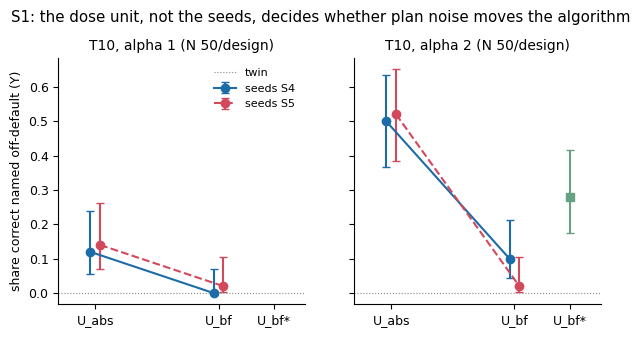

13:34:17|INFO   |figure F1_s1_interaction


In [25]:
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 8,
                     "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False, "axes.spines.right": False})
COL = {"D1": "#1b6ca8", "D2": "#5fa8d3", "D3": "#d1495b", "D4": "#edae49", "D5": "#66a182", "PTOP": "#2e294e",
       "PREST": "#8d6a9f", "PSHUF": "#999999", "TWIN": "#444444"}
NAME = {"D1": "D1 U_abs x S4", "D2": "D2 U_abs x S5", "D3": "D3 U_bf x S4", "D4": "D4 U_bf x S5",
        "D5": "D5 U_bf* x S4", "PTOP": "P_top", "PREST": "P_rest", "PSHUF": "P_shuf"}


def save(fig, name: str) -> None:
    fig.savefig(FIGS / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIGS / f"{name}.png", bbox_inches="tight", dpi=170)
    plt.show()                                    # demo: show inline (original: plt.close(fig))
    logger.info(f"figure {name}")


def f1(rows) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(7, 3.2), sharey=True)          # demo: T10 panels (original: 1 x 4)
    for ax, (task, alpha) in zip(axes, [("T10", 1.0), ("T10", 2.0)]):
        a = "a1" if alpha == 1 else "a2"
        for seeds, (du, db), ls in (("S4", ("D1", "D3"), "-"), ("S5", ("D2", "D4"), "--")):
            ys, lo, hi = [], [], []
            for d in (du, db):
                c = A.cell(rows, task, f"{d}_{a}", A.COMMITTED_KS[(task, alpha)])
                k = sum(r["Y"] for r in c.values())
                n = len(c)
                ys.append(k / n if n else np.nan)
                l, h = wilson(k, n)
                lo.append(max(0.0, ys[-1] - l))
                hi.append(max(0.0, h - ys[-1]))
            x = np.array([0, 1]) + (-0.04 if seeds == "S4" else 0.04)
            ax.errorbar(x, ys, yerr=[lo, hi], fmt="o", ls=ls, color="#1b6ca8" if seeds == "S4" else "#d1495b",
                        capsize=3, label=f"seeds {seeds}")
        c5 = A.cell(rows, task, f"D5_{a}", A.COMMITTED_KS[(task, alpha)])
        if c5:
            k = sum(r["Y"] for r in c5.values())
            n = len(c5)
            l, h = wilson(k, n)
            ax.errorbar([1.45], [k / n], yerr=[[max(0.0, k / n - l)], [max(0.0, h - k / n)]], fmt="s", color=COL["D5"], capsize=3,
                        label="U_bf* x S4 (D5)")
        tw = A.cell(rows, task, "TWIN", K.K20 if task == "T2" else K.K10)
        ax.axhline(sum(r["Y"] for r in tw.values()) / max(len(tw), 1), color="#888", lw=0.8, ls=":", label="twin")
        ax.set_xticks([0, 1, 1.45])
        ax.set_xticklabels(["U_abs", "U_bf", "U_bf*"])
        ax.set_title(f"{task}, alpha {int(alpha)} (N {len(A.cell(rows, task, f'D1_{a}', A.COMMITTED_KS[(task, alpha)]))}/design)")
        ax.set_xlim(-0.3, 1.7)
    axes[0].set_ylabel("share correct named off-default (Y)")
    axes[0].legend(loc="upper right", frameon=False)
    fig.suptitle("S1: the dose unit, not the seeds, decides whether plan noise moves the algorithm", y=1.03)
    save(fig, "F1_s1_interaction")


f1(rows)

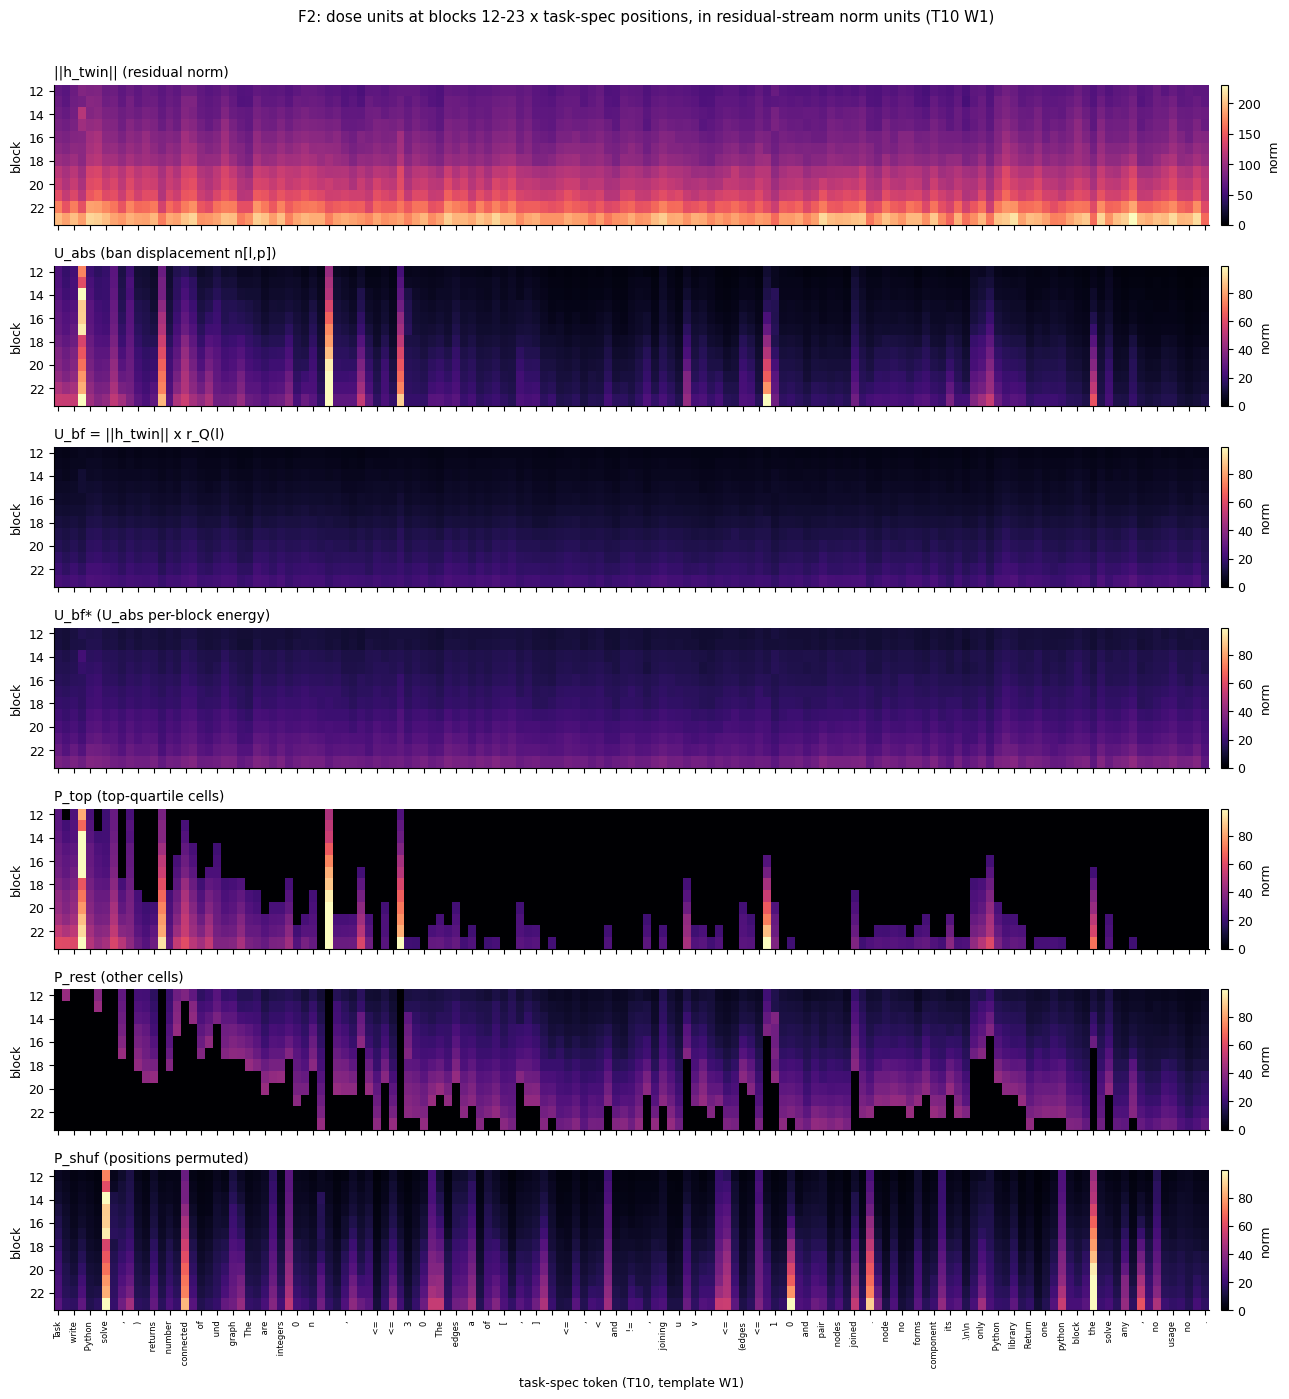

13:34:19|INFO   |figure F2_unit_heatmaps


In [26]:
def f2() -> None:
    # demo: the maps come from section 5 of this notebook (original: np.load(cache/units/T10.npz))
    z = {"tokens_W1": np.array(units["tokens_W1"]), "h_norm_W1": np.array(units["h_norm_W1"], dtype=np.float32),
         "U_abs": n_abs, "U_bf_W1": u_bf_w1, "U_bf_star_W1": bf_star(u_bf_w1, n_abs), "P_top": prof["P_top"]["unit"],
         "P_rest": prof["P_rest"]["unit"], "P_shuf": prof["P_shuf"]["unit"]}
    toks = [t.replace("\n", "\\n") for t in z["tokens_W1"]]
    mats = [("||h_twin|| (residual norm)", z["h_norm_W1"]), ("U_abs (ban displacement n[l,p])", z["U_abs"]),
            ("U_bf = ||h_twin|| x r_Q(l)", z["U_bf_W1"]), ("U_bf* (U_abs per-block energy)", z["U_bf_star_W1"]),
            ("P_top (top-quartile cells)", z["P_top"]), ("P_rest (other cells)", z["P_rest"]),
            ("P_shuf (positions permuted)", z["P_shuf"])]
    fig, axes = plt.subplots(len(mats), 1, figsize=(13, 2.0 * len(mats)), sharex=True)
    vmax = max(float(np.percentile(m, 99.5)) for _, m in mats[1:])
    for ax, (title, m) in zip(axes, mats):
        im = ax.imshow(m, aspect="auto", cmap="magma", vmin=0, vmax=(None if title.startswith("||h") else vmax),
                       interpolation="nearest")
        ax.set_yticks(range(0, 12, 2))
        ax.set_yticklabels([str(12 + i) for i in range(0, 12, 2)])
        ax.set_ylabel("block")
        ax.set_title(title, loc="left")
        plt.colorbar(im, ax=ax, pad=0.01, fraction=0.02, label="norm")
    step = max(1, len(toks) // 60)
    axes[-1].set_xticks(range(0, len(toks), step))
    axes[-1].set_xticklabels([toks[i][:10] for i in range(0, len(toks), step)], rotation=90, fontsize=6)
    axes[-1].set_xlabel("task-spec token (T10, template W1)")
    fig.suptitle("F2: dose units at blocks 12-23 x task-spec positions, in residual-stream norm units (T10 W1)", y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.985))
    save(fig, "F2_unit_heatmaps")


f2()

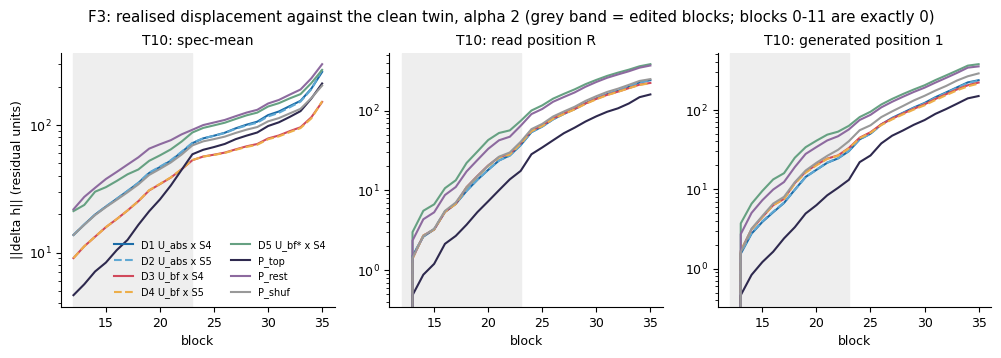

13:34:20|INFO   |figure F3_displacement_blocks


In [27]:
def f3() -> None:
    # demo: the 36-block profiles of the alpha-2 rows on the committed slots come from the data file (original: every
    # row of data/realised_disp.jsonl)
    rec = [{"task": e["metadata_task"], "alpha": parse_arm(arm)["alpha"], "design": parse_arm(arm)["design"], **p}
           for e in EX for arm, p in e["metadata_disp_profiles"].items()]
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), sharex=True)          # demo: the T10 row (original: 2 x 3)
    axes = axes[None, :]
    for i, task in enumerate(("T10",)):
        for j, (fld, lab) in enumerate((("spec_mean", "spec-mean"), ("R", "read position R"),
                                        ("gen1", "generated position 1"))):
            ax = axes[i, j]
            by = defaultdict(list)
            for r in rec:
                if r["task"] == task and r.get("alpha") == 2.0 and r.get(fld):
                    by[r["design"]].append(r[fld])
            for d in ("D1", "D2", "D3", "D4", "D5", "PTOP", "PREST", "PSHUF"):
                if by.get(d):
                    m = np.mean(np.array(by[d]), axis=0)
                    ax.plot(range(12, 36), m[12:], color=COL[d], label=NAME[d],
                            ls="--" if d in ("D2", "D4") else "-")
            ax.set_yscale("log")
            ax.axvspan(12, 23, color="#eee", zorder=0)
            ax.set_title(f"{task}: {lab}")
            if j == 0:
                ax.set_ylabel("||delta h|| (residual units)")
            if i == 0:                                                       # demo: one row (original: i == 1)
                ax.set_xlabel("block")
    axes[0, 0].legend(frameon=False, ncol=2, fontsize=7)
    fig.suptitle("F3: realised displacement against the clean twin, alpha 2 (grey band = edited blocks; blocks 0-11 are exactly 0)", y=1.01)
    save(fig, "F3_displacement_blocks")


f3()

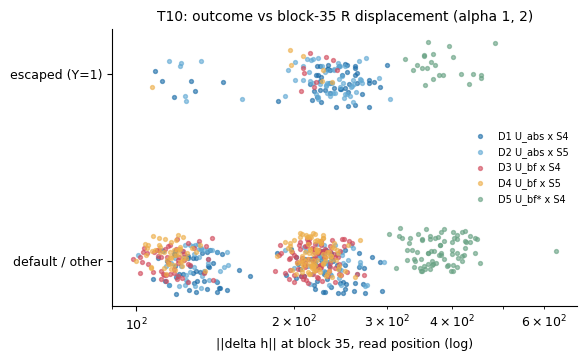

13:34:20|INFO   |figure F4_escape_vs_disp


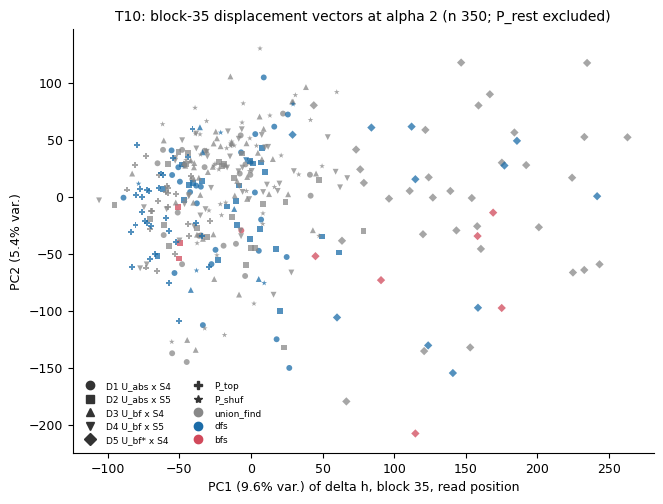

13:34:21|INFO   |figure F5_pca_disp35


In [28]:
def f4(rows) -> None:
    fig, axes = plt.subplots(1, 1, figsize=(6, 3.6))                        # demo: T10 only (original: 1 x 2)
    axes = [axes]
    rng = np.random.default_rng(0)
    for ax, task in zip(axes, ("T10",)):
        for i, d in enumerate(("D1", "D2", "D3", "D4", "D5")):
            sel = [r for r in rows if r["task"] == task and r["design"] == d and r.get("labelled")
                   and r.get("realised_disp") and r["alpha"] in (1.0, 2.0)]
            if not sel:
                continue
            x = np.array([r["realised_disp"]["R_b35"] for r in sel])
            y = np.array([r["Y"] for r in sel]) + rng.uniform(-0.12, 0.12, len(sel)) + (i - 2) * 0.03
            ax.scatter(x, y, s=8, alpha=0.6, color=COL[d], label=NAME[d])
        ax.set_yticks([0, 1])
        ax.set_yticklabels(["default / other", "escaped (Y=1)"])
        ax.set_xscale("log")
        ax.set_xlabel("||delta h|| at block 35, read position (log)")
        ax.set_title(f"{task}: outcome vs block-35 R displacement (alpha 1, 2)")
    axes[0].legend(frameon=False, fontsize=7, loc="center right")
    save(fig, "F4_escape_vs_disp")


def f5(rows) -> None:
    lab = {r["key"]: r for r in rows}
    vecs = defaultdict(dict)
    for key, v in load_vectors().items():          # demo: decoded from the data file (original: cache/disp/*.npz)
        vecs[key.split("|")[0]][key] = v["R35"]
    fig, axes = plt.subplots(1, 1, figsize=(7.5, 5.5))                      # demo: T10 only (original: 1 x 2)
    axes = [axes]
    marks = {"D1": "o", "D2": "s", "D3": "^", "D4": "v", "D5": "D", "PTOP": "P", "PREST": "X", "PSHUF": "*"}
    cmap = {"union_find": "#888888", "dfs": "#1b6ca8", "bfs": "#d1495b", "dijkstra": "#888888", "bf_spfa": "#1b6ca8",
            "other": "#66a182", "invalid": "#edae49", "floyd": "#8d6a9f", "disputed": "#000000"}
    for ax, task in zip(axes, ("T10",)):
        keys = [k for k in vecs.get(task, {}) if k in lab and lab[k].get("labelled") and lab[k]["alpha"] == 2.0
                and lab[k]["design"] != "PREST"]     # P_rest breaks T2 (pass 0) and would own PC1
        if len(keys) < 10:
            continue
        X = np.stack([vecs[task][k] for k in keys])
        Xc = X - X.mean(0)
        U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
        pcs = Xc @ Vt[:2].T
        ev = (S ** 2) / (S ** 2).sum()
        for d, mk in marks.items():
            for lb, c in cmap.items():
                idx = [i for i, k in enumerate(keys) if lab[k]["design"] == d and lab[k]["label"] == lb]
                if idx:
                    ax.scatter(pcs[idx, 0], pcs[idx, 1], marker=mk, s=18, color=c, alpha=0.75, edgecolor="none")
        from matplotlib.lines import Line2D
        h1 = [Line2D([], [], marker=mk, ls="", color="#333", label=NAME[d]) for d, mk in marks.items()
              if any(lab[k]["design"] == d for k in keys)]
        h2 = [Line2D([], [], marker="o", ls="", color=c, label=lb) for lb, c in cmap.items()
              if any(lab[k]["label"] == lb for k in keys)]
        ax.legend(handles=h1 + h2, frameon=False, fontsize=6.5, ncol=2, loc="best")
        ax.set_xlabel(f"PC1 ({100 * ev[0]:.1f}% var.) of delta h, block 35, read position")
        ax.set_ylabel(f"PC2 ({100 * ev[1]:.1f}% var.)")
        ax.set_title(f"{task}: block-35 displacement vectors at alpha 2 (n {len(keys)}; P_rest excluded)")
    save(fig, "F5_pca_disp35")


f4(rows)
f5(rows)

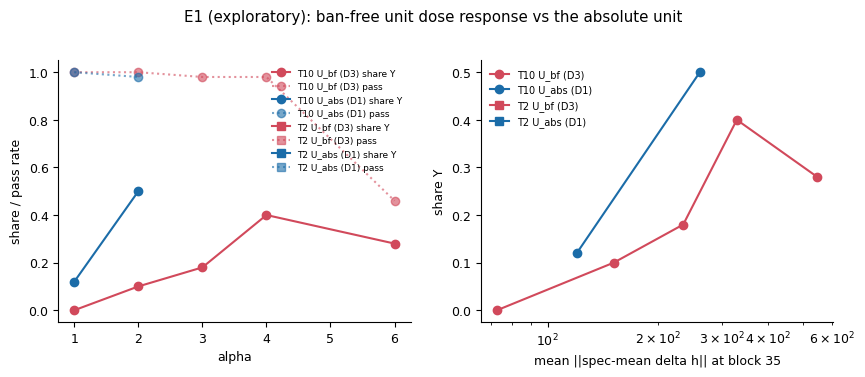

13:34:21|INFO   |figure E1_dose_response


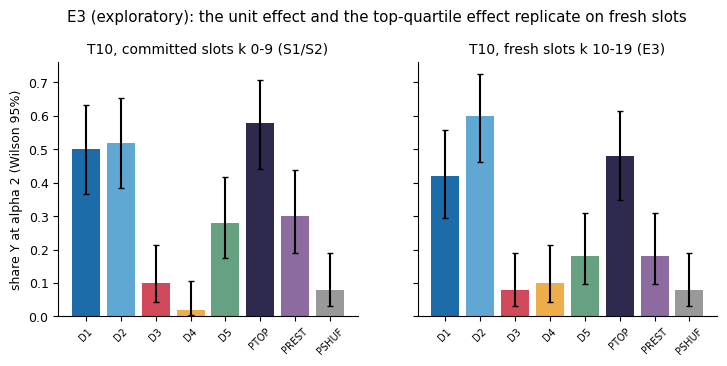

13:34:22|INFO   |figure E3_replicate


In [29]:
def e1() -> None:
    p = RESULTS / "e1_sweep.json"
    if not p.exists():
        return
    r = read_json(p)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    for task, mk in (("T10", "o"), ("T2", "s")):
        d = r.get(task, {})
        for unit, arms, c in (("U_bf (D3)", ["D3_a1", "D3_a2", "D3_a3", "D3_a4", "D3_a6"], "#d1495b"),
                              ("U_abs (D1)", ["D1_a1", "D1_a2"], "#1b6ca8")):
            xs = [float(a.split("_a")[1]) for a in arms if a in d]
            ys = [d[a]["Y"]["share"] for a in arms if a in d]
            ps = [d[a]["pass_rate"] for a in arms if a in d]
            dx = [d[a]["realised_mean"]["S_b35"] for a in arms if a in d and d[a].get("realised_mean")]
            axes[0].plot(xs, ys, marker=mk, color=c, label=f"{task} {unit} share Y")
            axes[0].plot(xs, ps, marker=mk, color=c, ls=":", alpha=0.6, label=f"{task} {unit} pass")
            if len(dx) == len(ys):
                axes[1].plot(dx, ys, marker=mk, color=c, label=f"{task} {unit}")
    axes[0].set_xlabel("alpha")
    axes[0].set_ylabel("share / pass rate")
    axes[0].legend(frameon=False, fontsize=6.5)
    axes[1].set_xlabel("mean ||spec-mean delta h|| at block 35")
    axes[1].set_ylabel("share Y")
    axes[1].set_xscale("log")
    axes[1].legend(frameon=False, fontsize=7)
    fig.suptitle("E1 (exploratory): ban-free unit dose response vs the absolute unit", y=1.03)
    save(fig, "E1_dose_response")


def e3() -> None:
    p = RESULTS / "e3_replicate.json"
    if not p.exists():
        return
    r = read_json(p)
    fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.3), sharey=True)        # demo: the two T10 panels (original: + T03)
    for ax, (lab, title) in zip(axes, (("T10_k0_9", "T10, committed slots k 0-9 (S1/S2)"),
                                       ("T10_fresh_k10_19", "T10, fresh slots k 10-19 (E3)"))):
        if lab == "T10_k0_9":
            s1 = read_json(RESULTS / "s1_2x2.json")["cells"]
            s2 = read_json(RESULTS / "s2_profile.json")["T10"]["cells"]
            cells = {d: s1[f"T10|{d}_a2"] for d in ("D1", "D2", "D3", "D4", "D5")} | {
                {"PTOP": "PTOP", "PREST": "PREST", "PSHUF": "PSHUF"}[k]: v for k, v in s2.items() if k != "D1"}
        elif lab == "T03_k0_9":
            cells = r[lab]["cells"]
        else:
            cells = r[lab]["profiles"]["cells"] | {d: v for d, v in r[lab].get("cells", {}).items()}
            s1c = {}
            n_sl = r[lab]["2x2|Y"]["n_slots"]
            for d in ("D2", "D3", "D4"):
                t = r[lab]["2x2|Y"]["shares"][d]
                s1c[d] = {"Y": {"share": t, "wilson95": list(wilson(int(round(t * n_sl)), n_sl))}}
            cells = {**s1c, **cells}
        order = [d for d in ("D1", "D2", "D3", "D4", "D5", "PTOP", "PREST", "PSHUF") if d in cells]
        ys = [cells[d]["Y"]["share"] for d in order]
        lo = [max(0.0, cells[d]["Y"]["share"] - cells[d]["Y"]["wilson95"][0]) for d in order]
        hi = [max(0.0, cells[d]["Y"]["wilson95"][1] - cells[d]["Y"]["share"]) for d in order]
        ax.bar(range(len(order)), ys, yerr=[lo, hi], color=[COL[d] for d in order], capsize=2)
        ax.set_xticks(range(len(order)))
        ax.set_xticklabels(order, rotation=45, fontsize=7)
        ax.set_title(title)
    axes[0].set_ylabel("share Y at alpha 2 (Wilson 95%)")
    fig.suptitle("E3 (exploratory): the unit effect and the top-quartile effect replicate on fresh slots", y=1.04)
    save(fig, "E3_replicate")


e1()
e3()

## 15. Summary: this notebook vs the artifact's published numbers
The table below compares every headline quantity recomputed above with the value in the artifact's `results/*.json`. The counts, shares, McNemar tables and decisions are deterministic and must match exactly. Bootstrap CIs and Monte-Carlo p-values match only at the original `N_BOOT = 2000` and `N_FLIP = 100_000`.

In [30]:
pub = data["metadata"]["published"]
t2, p2 = s1_res["tables"]["T10|a2|Y"], pub["s1_tables_T10"]["T10|a2|Y"]
fmt_ci = lambda rd, ci: f"{rd:+.3f} [{ci[0]:+.2f}, {ci[1]:+.2f}]"  # noqa: E731
fmt_rd = lambda v, c: fmt_ci(v[c], v[c + "_ci95"])  # noqa: E731
d5n, d5p = s1_res["D5_split"]["T10|Y"], pub["D5_split_T10"]["T10|Y"]
PRO, ENE = "profile_at_matched_energy (D1 - D5)", "energy_at_banfree_shape (D5 - D3)"
s2n, s2p = s2_res["T10"]["tests"], pub["s2_T10"]["tests"]
mcn = lambda t: f"{t['share_x']:.2f} vs {t['share_y']:.2f} ({t['n10']}:{t['n01']}, p {t['p']:.2g})"  # noqa: E731
e3n, e3p = e3_res["T10_fresh_k10_19"]["2x2|Y"], pub["e3_T10"]["T10_fresh_k10_19"]["2x2|Y"]
e3pn, e3pp = e3_res["T10_pooled_k0_19"]["2x2|Y"], pub["e3_T10"]["T10_pooled_k0_19"]["2x2|Y"]
scn, scp = e2_res["slot_concordance"], pub["e2_slot_concordance"]
stn, stp = e2_res["T10"]["fixed_dose_strata"], pub["e2_T10"]["fixed_dose_strata"]
e1n, e1p = e1_res["T10"], pub["e1_T10"]
summary_rows = [
    ("A1: D1 attempted off-default, T10 a2 (exp29 25/50)", f"{anchor_res['A1']['attempted_off_default']}/50",
     f"{pub['anchors']['A1']['attempted_off_default']}/50"),
    ("A1: per-slot label agreement with exp29", f"{anchor_res['D1_T10_per_slot_agreement_vs_exp29']['agreement']:.2f}",
     f"{pub['anchors']['D1_T10_per_slot_agreement_vs_exp29']['agreement']:.2f}"),
    ("A2: D4 correct off-default (exp27 1/50)", f"{anchor_res['A2']['correct_off_default']}/50",
     f"{pub['anchors']['A2']['correct_off_default']}/50"),
    ("S1 shares Y, D1/D2/D3/D4, T10 a2", "/".join(f"{t2['shares'][d]:.2f}" for d in ("D1", "D2", "D3", "D4")),
     "/".join(f"{p2['shares'][d]:.2f}" for d in ("D1", "D2", "D3", "D4"))),
    ("S1 unit effect RD [95% CI]", fmt_rd(t2, "RD_unit"), fmt_rd(p2, "RD_unit")),
    ("S1 seed effect RD [95% CI]", fmt_rd(t2, "RD_seed"), fmt_rd(p2, "RD_seed")),
    ("S1 interaction [95% CI]", fmt_rd(t2, "RD_int"), fmt_rd(p2, "RD_int")),
    ("S1 Holm p, unit", f"{t2['holm']['unit']:.2g}", f"{p2['holm']['unit']:.2g}"),
    ("S1 conditional logit beta_unit", f"{t2['clogit']['coef']['unit']:.2f}", f"{p2['clogit']['coef']['unit']:.2f}"),
    ("S1 decision (committed rule)", s1_res["decision_T10_a2"], pub["s1_decision_T10_a2"]),
    ("D5 (U_bf*) share Y", f"{d5n['shares']['D5']:.2f}", f"{d5p['shares']['D5']:.2f}"),
    ("D5 split: profile at matched energy (D1-D5)", fmt_ci(d5n[PRO]["RD"], d5n[PRO]["ci95"]),
     fmt_ci(d5p[PRO]["RD"], d5p[PRO]["ci95"])),
    ("D5 split: energy at ban-free shape (D5-D3)", fmt_ci(d5n[ENE]["RD"], d5n[ENE]["ci95"]),
     fmt_ci(d5p[ENE]["RD"], d5p[ENE]["ci95"])),
    ("S2 P_top vs P_rest (Y, McNemar)", mcn(s2n["PTOP_vs_PREST|Y"]), mcn(s2p["PTOP_vs_PREST|Y"])),
    ("S2 D1 vs P_shuf (Y, McNemar)", mcn(s2n["D1_vs_PSHUF|Y"]), mcn(s2p["D1_vs_PSHUF|Y"])),
    ("S2 reading", s2_res["reading_T10"], pub["s2_reading_T10"]),
    ("E1 D3 (U_bf) Y at alpha 3 / 4 / 6", " / ".join(f"{e1n[a]['Y']['k']}" for a in ("D3_a3", "D3_a4", "D3_a6")),
     " / ".join(f"{e1p[a]['Y']['k']}" for a in ("D3_a3", "D3_a4", "D3_a6"))),
    ("E3 fresh slots k10-19: unit RD [95% CI]", fmt_rd(e3n, "RD_unit"), fmt_rd(e3p, "RD_unit")),
    ("E3 pooled k0-19: unit RD [95% CI]", fmt_rd(e3pn, "RD_unit"), fmt_rd(e3pp, "RD_unit")),
    ("E2 phi(D1, D2) same stream, Y / A", f"{scn['T10|Y|alpha2']['phi_D1_D2_same_stream_diff_u']:.2f} / {scn['T10|A|alpha2']['phi_D1_D2_same_stream_diff_u']:.2f}",
     f"{scp['T10|Y|alpha2']['phi_D1_D2_same_stream_diff_u']:.2f} / {scp['T10|A|alpha2']['phi_D1_D2_same_stream_diff_u']:.2f}"),
    ("E2 P(escape a2 | escape a1), same u", f"{scn['T10|A|D1_alpha1_to_alpha2_same_u_same_stream']['P_escape_a2_given_escape_a1']:.2f}",
     f"{scp['T10|A|D1_alpha1_to_alpha2_same_u_same_stream']['P_escape_a2_given_escape_a1']:.2f}"),
    ("E2 CV AUC, log norms, U_abs a2", f"{stn['U_abs_alpha2 (D1+D2)']['cv_auc_log_norms']:.3f}",
     f"{stp['U_abs_alpha2 (D1+D2)']['cv_auc_log_norms']:.3f}"),
    ("E2 CV AUC, R35 direction, U_abs a2 (randomized PCA)", f"{stn['U_abs_alpha2 (D1+D2)']['cv_auc_R35_direction']:.3f}",
     f"{stp['U_abs_alpha2 (D1+D2)']['cv_auc_R35_direction']:.3f}"),
]
summary_df = pd.DataFrame(summary_rows, columns=["quantity", "this notebook", "published (artifact)"])
summary_df["match"] = np.where(summary_df["this notebook"] == summary_df["published (artifact)"], "yes", "no")
summary_df.loc[summary_df["quantity"].str.contains("randomized PCA"), "match"] = "varies by run"   # see section 13
n_det = int((summary_df["match"] != "varies by run").sum())
print(f"N_BOOT = {N_BOOT}, N_FLIP = {N_FLIP}: {int((summary_df['match'] == 'yes').sum())}/{n_det} "
      f"deterministic quantities identical to the artifact\n")
print(summary_df.to_string(index=False))

N_BOOT = 2000, N_FLIP = 100000: 22/22 deterministic quantities identical to the artifact

                                           quantity                  this notebook           published (artifact)         match
 A1: D1 attempted off-default, T10 a2 (exp29 25/50)                          26/50                          26/50           yes
            A1: per-slot label agreement with exp29                           0.98                           0.98           yes
            A2: D4 correct off-default (exp27 1/50)                           1/50                           1/50           yes
                   S1 shares Y, D1/D2/D3/D4, T10 a2            0.50/0.52/0.10/0.02            0.50/0.52/0.10/0.02           yes
                         S1 unit effect RD [95% CI]          +0.450 [+0.35, +0.55]          +0.450 [+0.35, +0.55]           yes
                         S1 seed effect RD [95% CI]          +0.030 [-0.07, +0.14]          +0.030 [-0.07, +0.14]           yes
              

### What this notebook does not re-run
- **Generation.** Every program was generated by Qwen3-8B (bf16, about 0.66 GPU-hours on one RTX 4090) with the vendored exp22 engine and an exact inverse-CDF CRN sampler. The programs were then labelled by running them on hidden tests and classifying their algorithm. In the repository: `uv run method.py all`, after `hf download Qwen/Qwen3-8B --revision b968826d9c46dd6066d109eabc6255188de91218`.
- **The T2 half of S1/S2.** T2 is shortest weighted paths, default Dijkstra. It replicates the unit effect (+0.115 [0.06, 0.17]), with a caveat: one massive-activation cell dominates T2's U_abs.
- **D\* and the S3 prices.** These need all five tasks, the iteration-5 knob rows and exp27's full-simplex hull. Plan noise at D\* = D1 matches or beats base-model-written intents on 2 of 5 tasks (T03, T1); the committed prediction was 3. Iteration 5's rule, replayed, is still DISCONFIRMED, but the mean margin moves from −0.40 to +0.12.
- **The novelty audit.** All five correct "other" programs are catalogue variants: 0 novel algorithms.

In short, the S1 numbers above show that a random internal push moves Qwen3-8B off its default algorithm far more often when the push has the **shape of what a ban writes** than when it is spread flat over the prompt. A ban's shape is concentrated on the few task tokens where the ban's own displacement is largest.
- **Shape, not seeds.** Which seed scheme drew the direction does not matter.
- **Dose.** The flat, ban-free unit needs about twice the dose (α 4) to approach the ban-shaped unit at α 2, and at α 6 it breaks the programs.
- **Size, not mediator.** The size of the displacement that reaches the last block does not explain the difference.
- **Which samples escape is close to a coin flip per direction.**
- **No novelty.** The escapes land on *known* alternatives (DFS, BFS), not on novel algorithms.